# Tugas Besar 1 — Klasifikasi Keterlambatan Pengiriman E-Commerce Menggunakan Perceptron dan ADALINE

**Mata Kuliah:** Jaringan Syaraf Tiruan (IT6053)  
**Kelompok: Bebas**

| No | Nama | NIM |
|:--:|------|-----|
| 1 | Stefanus Westin Giovanno Mursito | 71241073 |
| 2 | Giovanni Albert Harjanto | 71241075 |
| 3 | Natalie Neysa Jessica Soesanto | 71241079 |
| 4 | Fransiska | 71241123 |
| 5 | Kevin Surya Saputra | 71241150 |

---

**Kasus:** Memprediksi apakah suatu pesanan e-commerce akan mengalami **keterlambatan pengiriman** (`late_delivery`) berdasarkan informasi yang tersedia *sebelum* hasil pengiriman diketahui. Masalah ini dirumuskan sebagai klasifikasi biner:

- **Kelas +1 (positif): Terlambat** — `late_delivery = 'Yes'`
- **Kelas −1: Tepat waktu** — `late_delivery = 'No'`

Dua model neuron tunggal — **Perceptron** (Rosenblatt, 1958) dan **ADALINE** dengan Delta Rule (Widrow & Hoff, 1960) — diimplementasikan secara mandiri menggunakan NumPy, dilatih pada delapan konfigurasi eksperimen, dan dievaluasi secara terukur.

## 1. Setup dan Keterulangan

Seluruh angka acak dikendalikan oleh satu `SEED`. Pembagian data, inisialisasi, dan urutan sampel identik untuk semua konfigurasi sehingga perbedaan hasil hanya berasal dari model, η, dan standardisasi. Versi paket dicetak agar eksperimen dapat diulang.

In [1]:
import os, sys, platform, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score)

# ---------------- Parameter eksperimen (ditetapkan SEBELUM melihat data uji) ----
SEED      = 42          # seed untuk split data & inisialisasi acak (pembanding)
TEST_SIZE = 0.20        # 80% latih : 20% uji
VAL_SIZE  = 0.20        # 20% dari data latih -> validasi (khusus seleksi model)
N_EPOCHS  = 50
ETAS      = [0.001, 0.01, 0.1]
DATA_PATH = 'dataset.csv'
FIG_DIR, RES_DIR = 'figures', 'results'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 150, 'axes.grid': True,
                     'grid.alpha': 0.3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
C_NEG, C_POS = '#2E86AB', '#E4572E'      # warna kelas -1 (tepat waktu) & +1 (terlambat)

def savefig(fig, name):
    """Simpan gambar ke folder figures/ untuk laporan & presentasi."""
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches='tight')

print(f"Python       : {sys.version.split()[0]} ({platform.system()} {platform.release()})")
for mod in (np, pd, matplotlib, sklearn):
    print(f"{mod.__name__:<13}: {mod.__version__}")
print(f"SEED         : {SEED}")

Python       : 3.13.7 (Windows 11)
numpy        : 2.3.2
pandas       : 2.3.2
matplotlib   : 3.10.6
sklearn      : 1.8.0
SEED         : 42


## 2. Masalah dan Dataset

### 2.1 Formulasi sebagai *supervised learning*

Keterlambatan pengiriman merupakan salah satu tantangan utama e-commerce karena memengaruhi kepuasan pelanggan dan biaya operasional. Pratama *et al.* (2025) menunjukkan bahwa klasifikasi ketepatan waktu pengiriman dengan algoritma supervised learning menghasilkan akurasi sekitar 64–66% pada data serupa, yang mengindikasikan hubungan non-linear yang kompleks antara fitur dan label.

Dalam tugas ini, masalah tersebut dirumuskan sebagai *supervised learning* (pembelajaran terawasi): diberikan vektor fitur masukan **x** ∈ ℝᵈ yang mendeskripsikan pesanan, model mempelajari fungsi keputusan f(**x**) → {−1, +1} yang memprediksi apakah pesanan akan terlambat (+1) atau tepat waktu (−1).

**Dataset:** *E-commerce Delivery & Shipping Data 2026* dari Kaggle (lisensi CC0 1.0 — domain publik, boleh disalin, dimodifikasi, dan didistribusikan tanpa izin).

- **Sumber:** https://www.kaggle.com/datasets/datascikhan/e-commerce-delivery-and-shipping-data-2026
- **Observasi:** 50.000 pesanan
- **Target:** `late_delivery` — dua kelas alami (`Yes` / `No`), sehingga tidak perlu memilih atau menggabungkan subset kelas.

#### Fitur masukan (14 fitur)

Data yang dipakai dalam eksperimen disimpan di `dataset.csv` (16 kolom: `order_id` + 14 fitur + target). Kolom yang baru diketahui setelah pengiriman selesai — `actual_delivery_days`, `delivery_delay_days`, `delivery_status`, `tracking_status`, `return_requested`, `return_reason`, `customer_rating`, dan `delivery_attempts` — **tidak digunakan** sebagai fitur karena berpotensi bocor (*data leakage*). Kolom identitas dan lokasi (`customer_id`, kota, negara, gudang, `order_date`) juga tidak dipakai.

Tabel kamus fitur:

In [2]:
df = pd.read_csv(DATA_PATH)

NUM_FEATURES = ['product_weight_kg', 'order_value_usd', 'distance_km',
                'promised_delivery_days', 'shipping_cost_usd',
                'warehouse_processing_hours']
ORD_FEATURES = {  # kategori ordinal -> urutan alami (indeks 0, 1, 2, 3)
    'package_size':   ['Small', 'Medium', 'Large', 'Oversized'],
    'order_priority': ['Low', 'Normal', 'High', 'Urgent'],
}
NOM_FEATURES = ['customer_segment', 'product_category', 'shipping_method',
                'carrier', 'payment_method', 'weather_condition']
CAT_FEATURES = list(ORD_FEATURES) + NOM_FEATURES
TARGET    = 'late_delivery'
POS_LABEL = 1        # kelas positif: +1 = Terlambat (late_delivery == 'Yes')
LABELS    = [-1, 1]  # urutan label pada confusion matrix
LABEL_NAME = {-1: 'Tepat waktu (-1)', 1: 'Terlambat (+1)'}

y_all = np.where(df[TARGET] == 'Yes', 1, -1).astype(int)

print(f"Jumlah observasi : {df.shape[0]:,}")
print(f"Jumlah kolom     : {df.shape[1]} (order_id + {len(NUM_FEATURES)} numerik + "
      f"{len(CAT_FEATURES)} kategorikal + target)")
df.head()

Jumlah observasi : 50,000
Jumlah kolom     : 16 (order_id + 6 numerik + 8 kategorikal + target)


,order_id,product_weight_kg,order_value_usd,distance_km,promised_delivery_days,shipping_cost_usd,warehouse_processing_hours,customer_segment,product_category,shipping_method,carrier,package_size,payment_method,order_priority,weather_condition,late_delivery
0,ORD-000001,8.23,10.39,1579.5,11,133.10,25.1,Small Business,Home & Kitchen,International,EagleCourier,Large,Digital Wallet,Normal,Snow,Yes
1,ORD-000002,0.10,117.69,1049.0,5,26.95,25.9,Consumer,Beauty,Standard,BlueRoute,Small,Debit Card,Normal,Cloudy,No
2,ORD-000003,5.51,335.23,4552.6,12,338.62,31.5,Consumer,Home & Kitchen,International,SpeedyCargo,Large,Debit Card,Low,Snow,Yes
3,ORD-000004,3.75,10.57,7074.9,8,270.45,12.6,Small Business,Grocery,Standard,ParcelPro,Large,Debit Card,Normal,Snow,Yes
4,ORD-000005,0.10,31.37,522.0,8,12.90,24.9,Small Business,Beauty,Economy,GlobalExpress,Small,Credit Card,Normal,Storm,Yes


In [3]:
feature_dict = pd.DataFrame([
    ('order_id', 'Identitas', 'ID pesanan (bukan fitur, hanya pelacak baris)'),
    ('product_weight_kg', 'Numerik', 'Berat produk (kg)'),
    ('order_value_usd', 'Numerik', 'Nilai pesanan (USD)'),
    ('distance_km', 'Numerik', 'Jarak gudang ke pelanggan (km)'),
    ('promised_delivery_days', 'Numerik', 'Estimasi hari pengiriman yang dijanjikan saat checkout'),
    ('shipping_cost_usd', 'Numerik', 'Biaya pengiriman (USD)'),
    ('warehouse_processing_hours', 'Numerik', 'Lama pemrosesan di gudang sebelum dikirim (jam)'),
    ('customer_segment', 'Kategorikal nominal', 'Consumer / Enterprise / Premium / Small Business'),
    ('product_category', 'Kategorikal nominal', '12 kategori produk'),
    ('shipping_method', 'Kategorikal nominal', 'Economy / Express / International / Same Day / Standard'),
    ('carrier', 'Kategorikal nominal', '8 perusahaan kurir'),
    ('package_size', 'Kategorikal ordinal', 'Small < Medium < Large < Oversized'),
    ('payment_method', 'Kategorikal nominal', '6 metode pembayaran'),
    ('order_priority', 'Kategorikal ordinal', 'Low < Normal < High < Urgent'),
    ('weather_condition', 'Kategorikal nominal', 'Clear / Cloudy / Extreme Heat / Rain / Snow / Storm'),
    ('late_delivery', 'Target', "'Yes' -> +1 (Terlambat, kelas positif); 'No' -> -1 (Tepat waktu)"),
], columns=['Kolom', 'Tipe', 'Makna'])
feature_dict

,Kolom,Tipe,Makna
0,order_id,Identitas,"ID pesanan (bukan fitur, hanya pelacak baris)"
1,product_weight_kg,Numerik,Berat produk (kg)
2,order_value_usd,Numerik,Nilai pesanan (USD)
3,distance_km,Numerik,Jarak gudang ke pelanggan (km)
4,promised_delivery_days,Numerik,Estimasi hari pengiriman yang dijanjikan saat ...
5,shipping_cost_usd,Numerik,Biaya pengiriman (USD)
6,warehouse_processing_hours,Numerik,Lama pemrosesan di gudang sebelum dikirim (jam)
7,customer_segment,Kategorikal nominal,Consumer / Enterprise / Premium / Small Business
8,product_category,Kategorikal nominal,12 kategori produk
9,shipping_method,Kategorikal nominal,Economy / Express / International / Same Day /...


### 2.2 Kualitas data: missing value, duplikasi, distribusi kelas

In [4]:
quality = pd.DataFrame({'dtype': df.dtypes.astype(str),
                        'missing': df.isna().sum(),
                        'nilai_unik': df.nunique()})
display(quality.T)

feat_cols = NUM_FEATURES + CAT_FEATURES
print('Total missing value              :', int(df.isna().sum().sum()))
print('Duplikat baris penuh             :', int(df.duplicated().sum()))
print('Duplikat order_id                :', int(df['order_id'].duplicated().sum()))
print('Duplikat kombinasi fitur saja    :', int(df[feat_cols].duplicated().sum()))
conflict = df.groupby(feat_cols, observed=True)[TARGET].nunique().gt(1).sum()
print('Fitur identik tetapi label beda  :', int(conflict))

class_dist = (pd.Series(y_all).map(LABEL_NAME).value_counts()
              .rename_axis('Kelas').to_frame('Jumlah'))
class_dist['Proporsi (%)'] = (100 * class_dist['Jumlah'] / len(y_all)).round(2)
display(class_dist)

,order_id,product_weight_kg,order_value_usd,distance_km,promised_delivery_days,shipping_cost_usd,warehouse_processing_hours,customer_segment,product_category,shipping_method,carrier,package_size,payment_method,order_priority,weather_condition,late_delivery
dtype,object,float64,float64,float64,int64,float64,float64,object,object,object,object,object,object,object,object,object
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
nilai_unik,50000,2075,24291,33059,16,22964,471,4,12,5,8,4,6,4,6,2


Total missing value              : 0
Duplikat baris penuh             : 0
Duplikat order_id                : 0


Duplikat kombinasi fitur saja    : 0
Fitur identik tetapi label beda  : 0


,Jumlah,Proporsi (%)
Kelas,,
Terlambat (+1),28162,56.32
Tepat waktu (-1),21838,43.68


In [5]:
df[NUM_FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
product_weight_kg,50000.0,2.255,3.695,0.10,0.320,0.93,2.610,52.19
order_value_usd,50000.0,177.917,291.600,10.00,28.720,76.84,173.162,3530.73
distance_km,50000.0,2496.779,1774.633,40.00,1086.775,2182.80,3592.475,9553.60
promised_delivery_days,50000.0,7.198,3.680,0.00,4.000,6.00,11.000,15.00
shipping_cost_usd,50000.0,120.516,108.680,4.05,40.640,82.97,167.422,500.00
warehouse_processing_hours,50000.0,14.412,9.925,1.00,6.600,11.90,20.700,48.00


### 2.3 Eksplorasi singkat: fitur mana yang berkaitan dengan keterlambatan?

Grafik berikut dihitung dari **seluruh data** hanya untuk memahami pola (deskriptif). Tidak ada parameter model yang dipelajari dari sini.

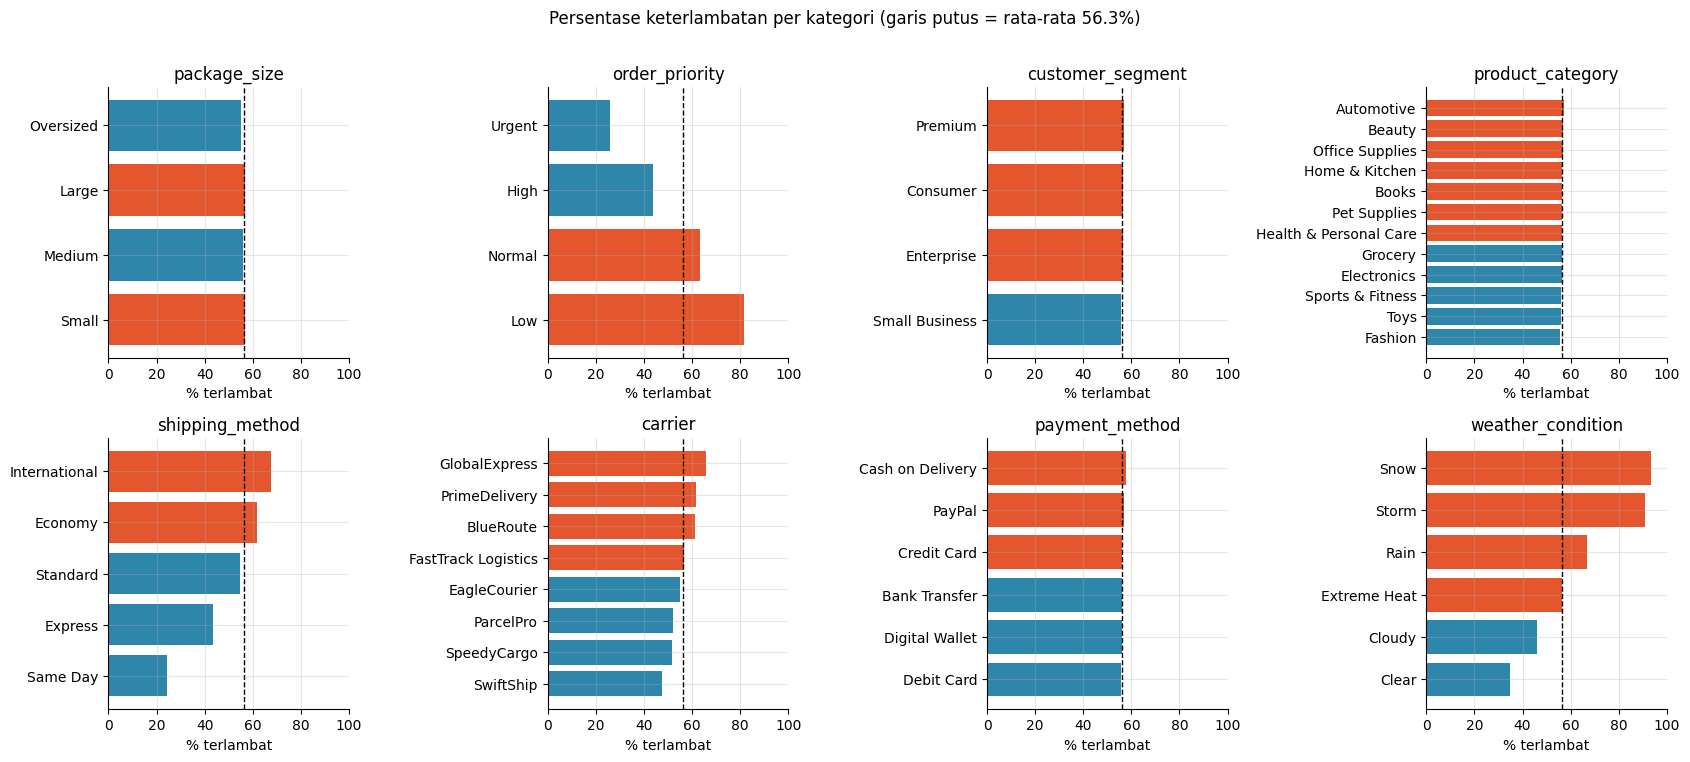

In [6]:
overall = (y_all == 1).mean()
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, col in zip(axes.ravel(), CAT_FEATURES):
    rate = (pd.Series(y_all == 1).groupby(df[col]).mean() * 100)
    if col in ORD_FEATURES:
        rate = rate.reindex(ORD_FEATURES[col])
    else:
        rate = rate.sort_values()
    ax.barh(rate.index.astype(str), rate.values,
            color=[C_POS if v > overall * 100 else C_NEG for v in rate.values])
    ax.axvline(overall * 100, color='k', ls='--', lw=1)
    ax.set_title(col); ax.set_xlim(0, 100); ax.set_xlabel('% terlambat')
fig.suptitle(f'Persentase keterlambatan per kategori (garis putus = rata-rata {overall:.1%})', y=1.01)
fig.tight_layout(); savefig(fig, '01_eda_kategori.png'); plt.show()

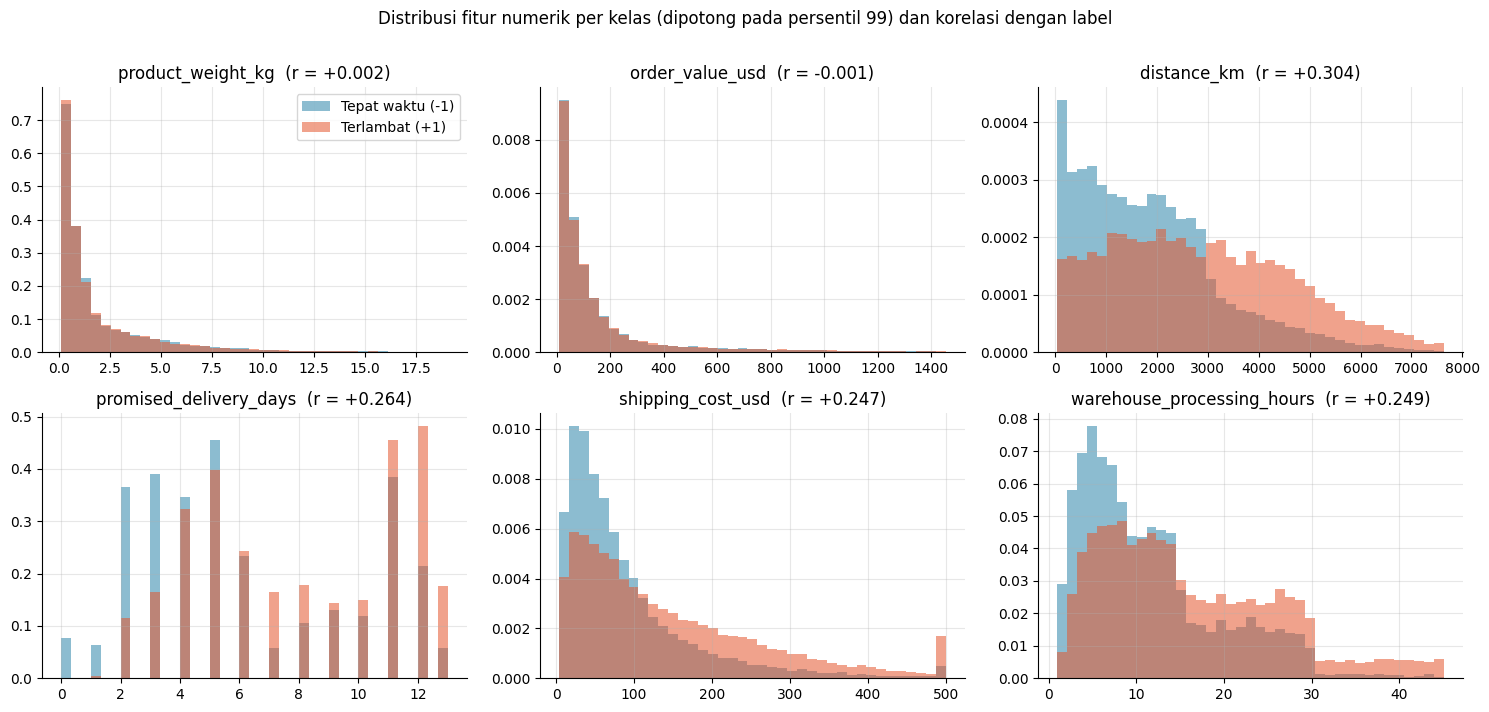

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), NUM_FEATURES):
    lo, hi = np.percentile(df[col], [0, 99])
    bins = np.linspace(lo, hi, 40)
    ax.hist(df.loc[y_all == -1, col], bins=bins, alpha=0.55, density=True, color=C_NEG, label='Tepat waktu (-1)')
    ax.hist(df.loc[y_all == 1, col], bins=bins, alpha=0.55, density=True, color=C_POS, label='Terlambat (+1)')
    r = np.corrcoef(df[col], y_all)[0, 1]
    ax.set_title(f'{col}  (r = {r:+.3f})')
axes[0, 0].legend()
fig.suptitle('Distribusi fitur numerik per kelas (dipotong pada persentil 99) dan korelasi dengan label', y=1.01)
fig.tight_layout(); savefig(fig, '02_eda_numerik.png'); plt.show()

## 3. Penyiapan Data dan Pencegahan Kebocoran

### 3.1 Pembagian data latih dan data uji

Data dibagi **80% latih : 20% uji** dengan **stratifikasi kelas** (`stratify=y`) dan `random_state=42` agar proporsi kelas identik di kedua subset. Pembagian ini **sama** untuk kedua model (Perceptron dan ADALINE) serta seluruh konfigurasi eksperimen.

### 3.2 Encoding fitur

Seluruh fitur harus numerik sebelum masuk ke neuron. Strategi encoding:

1. **Numerik (6 fitur):** dipakai apa adanya (imputasi median bila ada missing, dipelajari dari data latih).
2. **Ordinal (2 fitur):** `package_size` (Small=0, Medium=1, Large=2, Oversized=3) dan `order_priority` (Low=0, Normal=1, High=2, Urgent=3) — dipetakan ke indeks urutan alami.
3. **Nominal (6 fitur):** `customer_segment`, `product_category`, `shipping_method`, `carrier`, `payment_method`, `weather_condition` — *one-hot encoding* dengan *drop-first* (kategori pertama secara alfabetis pada data latih menjadi kategori acuan / semua nol). Ini menghasilkan jumlah kolom = jumlah kategori unik − 1 per fitur.

Total fitur setelah encoding: **43**.

### 3.3 Standardisasi (z-score)

Setiap fitur $x_j$ distandardisasi menjadi $x_j' = (x_j - \mu_j) / \sigma_j$, dengan $\mu_j$ dan $\sigma_j$ dihitung **hanya dari data latih**. Nilai yang sama diterapkan pada data uji tanpa menghitung ulang. Hal ini mencegah kebocoran informasi statistik data uji ke dalam proses pelatihan (LeCun *et al.*, 1998).

Eksperimen tanpa standardisasi menggunakan encoding yang sama tetapi **tanpa** langkah z-score, sehingga fitur berada pada skala aslinya.

In [8]:
idx_all = np.arange(len(df))
idx_train, idx_test = train_test_split(idx_all, test_size=TEST_SIZE,
                                       stratify=y_all, random_state=SEED)
df_train = df.iloc[idx_train].reset_index(drop=True)
df_test  = df.iloc[idx_test].reset_index(drop=True)
y_train, y_test = y_all[idx_train], y_all[idx_test]

assert len(np.intersect1d(idx_train, idx_test)) == 0, 'Ada kebocoran baris train/test!'

split_info = pd.DataFrame({
    'n': [len(y_train), len(y_test)],
    'n(+1) terlambat': [(y_train == 1).sum(), (y_test == 1).sum()],
    'n(-1) tepat waktu': [(y_train == -1).sum(), (y_test == -1).sum()],
    '% kelas +1': [100 * (y_train == 1).mean(), 100 * (y_test == 1).mean()],
}, index=['Latih', 'Uji']).round(2)
display(split_info)

# simpan daftar order_id per subset agar split dapat diperiksa ulang
pd.concat([pd.DataFrame({'order_id': df_train['order_id'], 'subset': 'train', 'train_order': np.arange(len(df_train))}),
           pd.DataFrame({'order_id': df_test['order_id'], 'subset': 'test', 'train_order': -1})]
          ).to_csv(os.path.join(RES_DIR, 'split_train_test.csv'), index=False)
print('5 order_id pertama pada urutan latih:', df_train['order_id'].head().tolist())

,n,n(+1) terlambat,n(-1) tepat waktu,% kelas +1
Latih,40000,22530,17470,56.32
Uji,10000,5632,4368,56.32


5 order_id pertama pada urutan latih: ['ORD-022265', 'ORD-000249', 'ORD-020811', 'ORD-002782', 'ORD-010788']


In [9]:
class Preprocessor:
    """Mengubah DataFrame mentah menjadi matriks fitur numerik X.

    Semua parameter -- median/modus untuk imputasi, daftar kategori one-hot,
    serta mean & simpangan baku untuk standardisasi -- dipelajari HANYA dari
    data yang diberikan ke fit() (data latih), lalu diterapkan apa adanya ke
    data uji melalui transform(). Ini mencegah kebocoran informasi data uji.

    Encoding:
      * numerik  -> apa adanya (imputasi median bila ada missing)
      * ordinal  -> indeks urutan alami (0, 1, 2, 3)
      * nominal  -> one-hot drop-first (kategori pertama secara alfabetis
                    pada data latih menjadi kategori acuan / semua nol)
    """

    def __init__(self, num_features, ord_features, nom_features, standardize=True):
        self.num_features = list(num_features)
        self.ord_features = dict(ord_features)
        self.nom_features = list(nom_features)
        self.cat_features = list(self.ord_features) + self.nom_features
        self.standardize = standardize

    def fit(self, data):
        self.num_median_ = data[self.num_features].median()
        self.cat_mode_ = {c: data[c].mode().iloc[0] for c in self.cat_features}
        self.categories_ = {c: sorted(data[c].dropna().unique()) for c in self.nom_features}
        self.reference_ = {c: cats[0] for c, cats in self.categories_.items()}
        self.feature_names_ = (self.num_features + list(self.ord_features) +
                               [f'{c}={v}' for c in self.nom_features
                                for v in self.categories_[c][1:]])
        X = self._encode(data)
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)          # ddof=0, sama seperti StandardScaler
        self.scale_[self.scale_ == 0] = 1.0  # jaga-jaga kolom konstan
        return self

    def _encode(self, data):
        blocks = [data[self.num_features].fillna(self.num_median_).to_numpy(dtype=float)]
        for c, order in self.ord_features.items():
            col = data[c].fillna(self.cat_mode_[c])
            if not col.isin(order).all():
                raise ValueError(f'Kategori tak dikenal pada {c}: {set(col) - set(order)}')
            blocks.append(col.map({v: i for i, v in enumerate(order)}).to_numpy(dtype=float)[:, None])
        for c in self.nom_features:
            col = data[c].fillna(self.cat_mode_[c]).to_numpy(dtype=object)
            cats = np.array(self.categories_[c][1:], dtype=object)
            blocks.append((col[:, None] == cats[None, :]).astype(float))  # kategori baru -> semua 0
        return np.hstack(blocks)

    def transform(self, data):
        X = self._encode(data)
        return (X - self.mean_) / self.scale_ if self.standardize else X

    def fit_transform(self, data):
        return self.fit(data).transform(data)

In [10]:
prep_std = Preprocessor(NUM_FEATURES, ORD_FEATURES, NOM_FEATURES, standardize=True).fit(df_train)
prep_raw = Preprocessor(NUM_FEATURES, ORD_FEATURES, NOM_FEATURES, standardize=False).fit(df_train)

X_train_std, X_test_std = prep_std.transform(df_train), prep_std.transform(df_test)
X_train_raw, X_test_raw = prep_raw.transform(df_train), prep_raw.transform(df_test)
FEATURE_NAMES = prep_std.feature_names_
N_FEATURES = len(FEATURE_NAMES)

print(f'X_train: {X_train_std.shape} | X_test: {X_test_std.shape} | jumlah fitur setelah encoding = {N_FEATURES}')
print('Kategori acuan (drop-first):', prep_std.reference_)

# Verifikasi 1: standardisasi buatan sendiri identik dengan StandardScaler (fit di data latih)
sc = StandardScaler().fit(X_train_raw)
assert np.allclose(sc.transform(X_test_raw), X_test_std)
# Verifikasi 2: hanya data latih yang tepat bermean 0 & std 1
print(f'Data latih : mean maks |{np.abs(X_train_std.mean(0)).max():.1e}|, std min-maks '
      f'{X_train_std.std(0).min():.3f}-{X_train_std.std(0).max():.3f}')
print(f'Data uji   : mean maks |{np.abs(X_test_std.mean(0)).max():.3f}|  '
      f'(tidak tepat 0 -> bukti scaler tidak melihat data uji)')

raw_scale = pd.DataFrame({'min': X_train_raw.min(0), 'max': X_train_raw.max(0),
                          'mean (dipakai scaler)': prep_std.mean_, 'std (dipakai scaler)': prep_std.scale_},
                         index=FEATURE_NAMES)
raw_scale.head(8).round(3)

X_train: (40000, 43) | X_test: (10000, 43) | jumlah fitur setelah encoding = 43
Kategori acuan (drop-first): {'customer_segment': 'Consumer', 'product_category': 'Automotive', 'shipping_method': 'Economy', 'carrier': 'BlueRoute', 'payment_method': 'Bank Transfer', 'weather_condition': 'Clear'}
Data latih : mean maks |3.3e-14|, std min-maks 1.000-1.000
Data uji   : mean maks |0.025|  (tidak tepat 0 -> bukti scaler tidak melihat data uji)


,min,max,mean (dipakai scaler),std (dipakai scaler)
product_weight_kg,0.10,52.19,2.260,3.705
order_value_usd,10.00,3530.73,176.643,288.693
distance_km,40.00,9477.10,2505.559,1773.404
promised_delivery_days,0.00,15.00,7.207,3.680
shipping_cost_usd,4.05,500.00,120.960,108.830
warehouse_processing_hours,1.00,48.00,14.400,9.915
package_size,0.00,3.00,1.109,0.899
order_priority,0.00,3.00,1.352,0.851


**Rentang skala tanpa standardisasi.** Tabel di atas menunjukkan kolom mentah berbeda skala hingga ribuan kali lipat (mis. `distance_km` sampai ~9.500, sedangkan fitur one-hot hanya 0/1). Perbedaan ini akan terlihat dampaknya pada eksperimen tanpa standardisasi.

**Indikasi awal separabilitas (PCA 2D).** Proyeksi data latih terstandardisasi ke dua komponen utama memberi gambaran awal apakah kedua kelas terpisah. PCA dihitung dengan SVD NumPy hanya dari data latih.

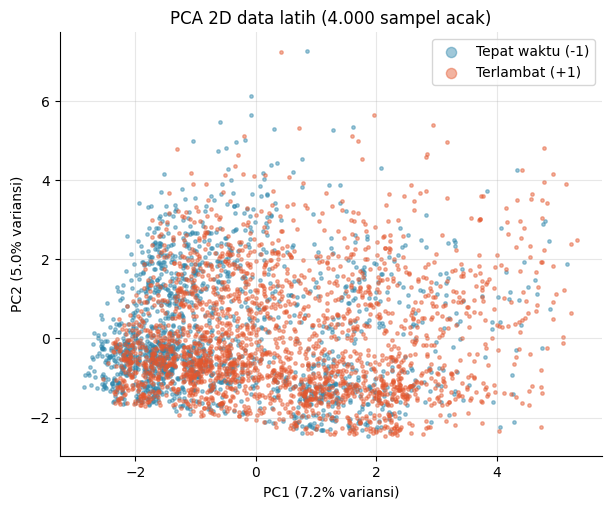

In [11]:
rng_plot = np.random.default_rng(SEED)
U, S, Vt = np.linalg.svd(X_train_std, full_matrices=False)      # X_train_std sudah bermean 0
pcs = X_train_std @ Vt[:2].T
expl = (S[:2] ** 2) / (S ** 2).sum()
sub = rng_plot.choice(len(pcs), 4000, replace=False)
fig, ax = plt.subplots(figsize=(7, 5.5))
for lab, c in [(-1, C_NEG), (1, C_POS)]:
    m = sub[y_train[sub] == lab]
    ax.scatter(pcs[m, 0], pcs[m, 1], s=6, alpha=0.45, c=c, label=LABEL_NAME[lab])
ax.set_xlabel(f'PC1 ({expl[0]:.1%} variansi)'); ax.set_ylabel(f'PC2 ({expl[1]:.1%} variansi)')
ax.set_title('PCA 2D data latih (4.000 sampel acak)'); ax.legend(markerscale=3)
savefig(fig, '03_pca_2d.png'); plt.show()

## 4. Model Neuron, Aturan Pembelajaran, dan Implementasi

### 4.1 Model neuron tunggal

Kedua model (Perceptron dan ADALINE) memakai neuron yang sama:

$$z = \mathbf{w}^T \mathbf{x} + b = \sum_{j=1}^{d} w_j x_j + b$$

di mana **w** = vektor bobot, *b* = bias, dan *z* = keluaran linear (*net input*). Prediksi kelas menggunakan **fungsi aktivasi ambang** (*threshold / sign*):

$$\hat{y} = \begin{cases} +1 & \text{jika } z \geq 0 \\ -1 & \text{jika } z < 0 \end{cases}$$

### 4.2 Perceptron (Rosenblatt, 1958)

Aturan pembaruan dihitung **per sampel** (online):

1. Hitung $z = \mathbf{w}^T \mathbf{x}_i + b$, lalu $\hat{y}_i = \text{sign}(z)$.
2. Jika $\hat{y}_i \neq y_i$ (salah klasifikasi): $\Delta = \eta (y_i - \hat{y}_i) \in \{+2\eta, -2\eta\}$. Perbarui: $\mathbf{w} \leftarrow \mathbf{w} + \Delta \mathbf{x}_i$; $b \leftarrow b + \Delta$.
3. Jika $\hat{y}_i = y_i$: $\Delta = 0$, tidak ada pembaruan.
4. Catat jumlah pembaruan (salah klasifikasi) di dalam setiap epoch.

**Error yang digunakan:** selisih label diskret $y_i - \hat{y}_i$ (bukan error kontinu). Pembaruan hanya terjadi saat ada kesalahan.

### 4.3 ADALINE — Delta Rule / LMS (Widrow & Hoff, 1960)

Aturan pembaruan dihitung **per batch** (seluruh data latih):

1. Hitung keluaran **linear** (bukan output ambang): $z_i = \mathbf{w}^T \mathbf{x}_i + b$ untuk semua sampel.
2. Error: $e_i = y_i - z_i$ — menggunakan **keluaran linear**, bukan keluaran ambang.
3. Fungsi objektif: $J = \frac{1}{2n} \sum_{i=1}^{n} e_i^2$. MSE $= \frac{1}{n}\sum e_i^2 = 2J$.
4. Pembaruan batch (gradient descent): $\mathbf{w} \leftarrow \mathbf{w} + \eta \frac{\mathbf{X}^T \mathbf{e}}{n}$; $b \leftarrow b + \eta \cdot \text{mean}(\mathbf{e})$.
5. **Ambang hanya dipakai saat prediksi**: $\hat{y} = \text{sign}(z)$, bukan saat menghitung error.

**Perbedaan mendasar dengan Perceptron:** ADALINE meminimalkan fungsi *loss* kontinu (J) dengan gradient, sehingga bobot bergerak ke arah yang mengurangi error rata-rata kuadrat. Perceptron hanya memperbaiki sampel yang salah, tanpa memperhatikan "seberapa jauh" prediksi dari batas keputusan.

### 4.4 Inisialisasi dan parameter pelatihan

| Parameter | Nilai |
|-----------|-------|
| Inisialisasi bobot & bias | Nol ($\mathbf{w}_0 = \mathbf{0}$, $b_0 = 0$) |
| Urutan sampel | Tetap (sesuai urutan indeks data latih setelah split) |
| Learning rate (η) | 0,001; 0,01; 0,1 |
| Epoch | 50 per konfigurasi |
| Pencatatan J (ADALINE) | Sesudah pembaruan setiap epoch + J₀ awal |
| Deteksi divergensi | Jika J atau bobot menjadi inf/NaN, pelatihan dihentikan dan epoch kejadian dicatat |

### 4.5 Implementasi mandiri (NumPy)

Kedua model diimplementasikan sebagai kelas Python di bawah ini. Kelas `Perceptron` dan `AdalineGD` **tidak** menggunakan fungsi pelatihan siap pakai dari scikit-learn atau mlxtend — hanya NumPy untuk operasi vektor/matriks. Fungsi scikit-learn (`train_test_split`, `accuracy_score`, `confusion_matrix`, dll.) dipakai untuk pembagian data dan evaluasi, bukan untuk pelatihan.

Kode rujukan yang diadaptasi: implementasi di bab 2 buku *Python Machine Learning* (Raschka & Mirjalili) dan dokumentasi mlxtend Adaline. Perubahan utama dari rujukan:
- Aturan pembaruan Perceptron menggunakan $\Delta = \eta(y - \hat{y})$ (bukan $\eta \cdot y$) sesuai panduan tugas.
- Ambang $z \geq 0 \to +1$ (bukan $z > 0$) sesuai panduan.
- Inisialisasi nol (bukan acak kecil).
- J = (1/2n)Σe² dicatat sesudah pembaruan setiap epoch.
- Deteksi divergensi (inf/NaN) ditambahkan.
- Pencatatan riwayat bobot dan jumlah pembaruan per epoch ditambahkan.

In [12]:
class Perceptron:
    """Perceptron Rosenblatt (implementasi NumPy mandiri).

    Neuron   : z = w^T x + b
    Aktivasi : y_hat = +1 jika z >= 0, selain itu -1 (fungsi ambang/sign)
    Update   : untuk SETIAP sampel (online), delta = eta * (y - y_hat)
               w <- w + delta * x ;  b <- b + delta
               (delta = 0 bila prediksi benar, +-2*eta bila salah)

    Parameter
    ---------
    eta        : learning rate (> 0)
    n_epochs   : jumlah putaran penuh atas data latih
    init       : 'zeros' (default) atau 'random' (N(0, init_scale))
    init_scale : simpangan baku inisialisasi acak
    random_state : seed untuk inisialisasi acak

    Atribut setelah fit
    -------------------
    w_, b_          : bobot & bias akhir
    updates_        : jumlah pembaruan (salah klasifikasi) di dalam tiap epoch
    train_errors_   : jumlah salah klasifikasi data latih SETELAH tiap epoch
    train_acc_      : akurasi latih SETELAH tiap epoch
    w_history_, b_history_ : parameter pada epoch 0 (awal) s.d. epoch terakhir
    """

    def __init__(self, eta=0.01, n_epochs=50, init='zeros', init_scale=0.01, random_state=42):
        self.eta, self.n_epochs = eta, n_epochs
        self.init, self.init_scale, self.random_state = init, init_scale, random_state

    def _init_params(self, n_features):
        if self.init == 'zeros':
            self.w_, self.b_ = np.zeros(n_features), 0.0
        elif self.init == 'random':
            r = np.random.default_rng(self.random_state).normal(0.0, self.init_scale, n_features + 1)
            self.w_, self.b_ = r[:-1].copy(), float(r[-1])
        else:
            raise ValueError("init harus 'zeros' atau 'random'")

    def net_input(self, X):
        return X @ self.w_ + self.b_

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
        self._init_params(X.shape[1])
        self.updates_, self.train_errors_, self.train_acc_ = [], [], []
        self.w_history_, self.b_history_ = [self.w_.copy()], [self.b_]
        for _ in range(self.n_epochs):
            n_updates = 0
            for xi, target in zip(X, y):                     # urutan sampel tetap
                y_hat = 1 if (xi @ self.w_ + self.b_) >= 0.0 else -1
                delta = self.eta * (target - y_hat)
                if delta != 0.0:                             # hanya saat salah klasifikasi
                    self.w_ += delta * xi
                    self.b_ += delta
                    n_updates += 1
            y_pred = self.predict(X)
            self.updates_.append(n_updates)
            self.train_errors_.append(int((y_pred != y).sum()))
            self.train_acc_.append(float((y_pred == y).mean()))
            self.w_history_.append(self.w_.copy()); self.b_history_.append(self.b_)
        self.epochs_completed_ = self.n_epochs
        return self

In [13]:
class AdalineGD:
    """ADALINE (Widrow-Hoff) dengan Delta Rule / batch gradient descent (NumPy mandiri).

    Neuron     : z = w^T x + b ; aktivasi linear (identitas) phi(z) = z
    Error      : e = y - z   (dari keluaran LINEAR, bukan dari keluaran ambang)
    Objektif   : J(w, b) = (1 / 2n) * sum(e_i^2)      ;  MSE = (1/n) * sum(e_i^2) = 2J
    Update     : w <- w + eta * X^T e / n ;  b <- b + eta * mean(e)   (satu kali per epoch)
    Prediksi   : ambang hanya dipakai di predict(): +1 jika z >= 0, selain itu -1

    Pencatatan : cost_[0] = J dengan parameter awal; cost_[k] = J SESUDAH pembaruan
                 epoch ke-k. Jika J/parameter menjadi inf atau NaN, pelatihan
                 dihentikan, epoch kejadian dicatat di diverged_epoch_, dan
                 parameter dikembalikan ke epoch terakhir yang masih berhingga.
    """

    def __init__(self, eta=0.01, n_epochs=50, init='zeros', init_scale=0.01, random_state=42):
        self.eta, self.n_epochs = eta, n_epochs
        self.init, self.init_scale, self.random_state = init, init_scale, random_state

    _init_params = Perceptron._init_params

    def net_input(self, X):
        return X @ self.w_ + self.b_

    @staticmethod
    def activation(z):
        return z                                         # linear

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

    @staticmethod
    def _cost(e):
        return float(e @ e) / (2 * e.shape[0])

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        n = X.shape[0]
        self._init_params(X.shape[1])
        e = y - self.activation(self.net_input(X))
        self.cost_ = [self._cost(e)]
        self.train_acc_ = [float((self.predict(X) == y).mean())]
        self.w_history_, self.b_history_ = [self.w_.copy()], [self.b_]
        self.diverged_epoch_ = None
        with np.errstate(over='ignore', invalid='ignore'):
            for epoch in range(1, self.n_epochs + 1):
                w_prev, b_prev = self.w_.copy(), self.b_
                e = y - self.activation(self.net_input(X))       # error linear (sebelum update)
                self.w_ = self.w_ + self.eta * (X.T @ e) / n
                self.b_ = self.b_ + self.eta * e.mean()
                J = self._cost(y - self.activation(self.net_input(X)))   # J sesudah update
                if not (np.isfinite(J) and np.all(np.isfinite(self.w_)) and np.isfinite(self.b_)):
                    self.diverged_epoch_ = epoch
                    self.w_, self.b_ = w_prev, b_prev
                    break
                self.cost_.append(J)
                self.train_acc_.append(float((self.predict(X) == y).mean()))
                self.w_history_.append(self.w_.copy()); self.b_history_.append(self.b_)
        self.mse_ = [2 * c for c in self.cost_]
        self.epochs_completed_ = len(self.cost_) - 1
        return self

### 4.6 Perhitungan manual

Untuk menunjukkan **mekanisme pembelajaran** secara transparan, berikut dua langkah pembaruan pada masing-masing model menggunakan **tiga fitur terstandardisasi** (`distance_km`, `promised_delivery_days`, `warehouse_processing_hours`) dan η = 0,1.

Contoh mini terdiri atas empat sampel dari data latih: dua sampel kelas −1 pertama dan dua sampel kelas +1 pertama menurut urutan latih, disusun berselang (−1, +1, −1, +1) agar kedua kelas muncul. Parameter awal w = 0 dan b = 0. Perceptron memproses S1 lalu S2 secara berurutan (per sampel). ADALINE memproses keempat sampel sekaligus (batch) selama 2 iterasi. Hasil hitungan langkah demi langkah kemudian diperiksa dengan `assert` agar identik dengan keluaran kelas `Perceptron` dan `AdalineGD` yang dipakai pada eksperimen.

In [14]:
MANUAL_FEATURES = ['distance_km', 'promised_delivery_days', 'warehouse_processing_hours']
ETA_MANUAL = 0.1
mcols = [FEATURE_NAMES.index(f) for f in MANUAL_FEATURES]
neg_first = np.where(y_train == -1)[0][:2]
pos_first = np.where(y_train == 1)[0][:2]
mini_idx = np.array([neg_first[0], pos_first[0], neg_first[1], pos_first[1]])
X_mini = X_train_std[mini_idx][:, mcols]
y_mini = y_train[mini_idx]

mini_df = pd.DataFrame(X_mini, columns=[f'x{j+1}: {f}' for j, f in enumerate(MANUAL_FEATURES)])
mini_df.insert(0, 'order_id', df_train['order_id'].values[mini_idx])
mini_df.insert(0, 'urutan latih', mini_idx)
mini_df.index = [f'S{k+1}' for k in range(4)]
mini_df['y'] = y_mini
mini_df.round(4)

,urutan latih,order_id,x1: distance_km,x2: promised_delivery_days,x3: warehouse_processing_hours,y
S1,5,ORD-016547,-0.1654,1.0307,-0.7766,-1
S2,0,ORD-022265,-0.4735,-1.1432,-0.8371,1
S3,6,ORD-035558,-0.0029,-0.3280,-0.3228,-1
S4,1,ORD-000249,0.9708,-0.0562,0.8472,1


In [15]:
def fmt(v):
    return '[' + ', '.join(f'{a:+.4f}' for a in np.atleast_1d(v)) + ']'

print('=== PERCEPTRON: 2 langkah pembaruan per-sampel (eta = 0.1, w0 = 0, b0 = 0) ===')
w, b = np.zeros(3), 0.0
for k in range(2):
    x, t = X_mini[k], y_mini[k]
    terms = [w[j] * x[j] for j in range(3)]
    z = sum(terms) + b
    y_hat = 1 if z >= 0 else -1
    delta = ETA_MANUAL * (t - y_hat)
    print(f'\nLangkah {k+1} (sampel S{k+1}, y = {t:+d})')
    print(f'  z = ' + ' + '.join(f'({w[j]:+.4f})({x[j]:+.4f})' for j in range(3)) + f' + ({b:+.4f}) = {z:+.4f}')
    print(f'  y_hat = {y_hat:+d}  ->  delta = {ETA_MANUAL} * ({t:+d} - ({y_hat:+d})) = {delta:+.4f}')
    w = w + delta * x
    b = b + delta
    print(f'  w = w + delta*x = {fmt(w)} ;  b = {b:+.4f}')
w_manual_p, b_manual_p = w.copy(), b

# Konsistensi dengan kode: kelas Perceptron 1 epoch atas S1, S2 harus identik
p_chk = Perceptron(eta=ETA_MANUAL, n_epochs=1).fit(X_mini[:2], y_mini[:2])
assert np.allclose(p_chk.w_, w_manual_p) and np.isclose(p_chk.b_, b_manual_p)
print(f'\nKelas Perceptron -> w = {fmt(p_chk.w_)}, b = {p_chk.b_:+.4f}, updates = {p_chk.updates_}  (IDENTIK)')

=== PERCEPTRON: 2 langkah pembaruan per-sampel (eta = 0.1, w0 = 0, b0 = 0) ===

Langkah 1 (sampel S1, y = -1)
  z = (+0.0000)(-0.1654) + (+0.0000)(+1.0307) + (+0.0000)(-0.7766) + (+0.0000) = +0.0000
  y_hat = +1  ->  delta = 0.1 * (-1 - (+1)) = -0.2000
  w = w + delta*x = [+0.0331, -0.2061, +0.1553] ;  b = -0.2000

Langkah 2 (sampel S2, y = +1)
  z = (+0.0331)(-0.4735) + (-0.2061)(-1.1432) + (+0.1553)(-0.8371) + (-0.2000) = -0.1100
  y_hat = -1  ->  delta = 0.1 * (+1 - (-1)) = +0.2000
  w = w + delta*x = [-0.0616, -0.4348, -0.0121] ;  b = +0.0000

Kelas Perceptron -> w = [-0.0616, -0.4348, -0.0121], b = +0.0000, updates = [2]  (IDENTIK)


In [16]:
print('=== ADALINE: 2 iterasi batch gradient descent (eta = 0.1, w0 = 0, b0 = 0, n = 4) ===')
w, b, n = np.zeros(3), 0.0, len(y_mini)
J_manual = [float(np.sum((y_mini - (X_mini @ w + b)) ** 2) / (2 * n))]
print(f'J awal (epoch 0) = (1/2n) sum(y - z)^2 = {J_manual[0]:.4f}')
for it in range(1, 3):
    z = np.array([sum(w[j] * X_mini[i, j] for j in range(3)) + b for i in range(n)])
    e = y_mini - z
    grad_w = np.array([sum(X_mini[i, j] * e[i] for i in range(n)) / n for j in range(3)])
    mean_e = e.sum() / n
    print(f'\nIterasi {it}')
    print(pd.DataFrame({'z_i': z, 'y_i': y_mini, 'e_i = y_i - z_i': e,
                        'x1*e': X_mini[:, 0] * e, 'x2*e': X_mini[:, 1] * e, 'x3*e': X_mini[:, 2] * e},
                       index=[f'S{i+1}' for i in range(n)]).round(4).to_string())
    print(f'  X^T e / n = {fmt(grad_w)} ;  mean(e) = {mean_e:+.4f}')
    w = w + ETA_MANUAL * grad_w
    b = b + ETA_MANUAL * mean_e
    J_after = float(np.sum((y_mini - (X_mini @ w + b)) ** 2) / (2 * n))
    J_manual.append(J_after)
    print(f'  w = w + eta * X^T e / n = {fmt(w)} ;  b = b + eta*mean(e) = {b:+.4f}')
    print(f'  J sesudah update = {J_after:.4f}   (MSE = {2 * J_after:.4f})')
w_manual_a, b_manual_a = w.copy(), b

a_chk = AdalineGD(eta=ETA_MANUAL, n_epochs=2).fit(X_mini, y_mini)
assert np.allclose(a_chk.w_, w_manual_a) and np.isclose(a_chk.b_, b_manual_a)
assert np.allclose(a_chk.cost_, J_manual)
print(f'\nKelas AdalineGD -> w = {fmt(a_chk.w_)}, b = {a_chk.b_:+.4f}, cost_ = {np.round(a_chk.cost_, 4)}  (IDENTIK)')

=== ADALINE: 2 iterasi batch gradient descent (eta = 0.1, w0 = 0, b0 = 0, n = 4) ===
J awal (epoch 0) = (1/2n) sum(y - z)^2 = 0.5000

Iterasi 1
    z_i  y_i  e_i = y_i - z_i    x1*e    x2*e    x3*e
S1  0.0   -1             -1.0  0.1654 -1.0307  0.7766
S2  0.0    1              1.0 -0.4735 -1.1432 -0.8371
S3  0.0   -1             -1.0  0.0029  0.3280  0.3228
S4  0.0    1              1.0  0.9708 -0.0562  0.8472
  X^T e / n = [+0.1664, -0.4755, +0.2774] ;  mean(e) = +0.0000
  w = w + eta * X^T e / n = [+0.0166, -0.0476, +0.0277] ;  b = b + eta*mean(e) = +0.0000
  J sesudah update = 0.4679   (MSE = 0.9358)

Iterasi 2
       z_i  y_i  e_i = y_i - z_i    x1*e    x2*e    x3*e
S1 -0.0733   -1          -0.9267  0.1532 -0.9551  0.7197
S2  0.0233    1           0.9767 -0.4625 -1.1166 -0.8177
S3  0.0066   -1          -1.0066  0.0029  0.3301  0.3249
S4  0.0423    1           0.9577  0.9297 -0.0539  0.8114
  X^T e / n = [+0.1558, -0.4489, +0.2596] ;  mean(e) = +0.0003
  w = w + eta * X^T e / n = [+

**Pengamatan dari perhitungan manual:**

1. **Perceptron, langkah 1.** Dengan w = 0 dan b = 0, z = 0. Karena aturan ambangnya z ≥ 0 → +1, S1 (y = −1) diprediksi +1 sehingga salah. Δ = 0,1·(−1 − 1) = −0,2, maka w bergeser ke arah −x₁ dan b menjadi −0,2.
2. **Perceptron, langkah 2.** S2 (y = +1) menghasilkan z = −0,1100 < 0 → ŷ = −1, salah lagi, sehingga Δ = +0,2. Besar langkah selalu tepat ±2η, berapa pun jarak z ke batas. Jika prediksi benar, Δ = 0 dan bobot tidak berubah.
3. **ADALINE** memakai error dari keluaran linear, e = y − z. Pada iterasi 1, z = 0 untuk semua sampel sehingga e = y. Rata-rata e = 0 karena dua sampel +1 dan dua sampel −1, sehingga b tetap 0. Bobot tetap berubah karena Xᵀe/n ≠ 0. Pada iterasi 2 error sudah mengecil (mis. e₁ = −0,9267) sehingga langkahnya juga mengecil.
4. J turun dari 0,5000 → 0,4679 → 0,4394. Ini menunjukkan gradient descent bergerak menuruni permukaan J. ADALINE tetap memperbarui bobot selama z ≠ y, walaupun tanda prediksinya mungkin sudah benar. Perceptron berhenti memperbarui bobot begitu tanda prediksinya benar.

## 5. Rancangan Eksperimen

Seluruh konfigurasi ditetapkan **sebelum** melihat data uji. Data uji hanya dipakai untuk pelaporan akhir, bukan untuk memilih parameter berulang kali.

### Enam konfigurasi terstandardisasi

| Model | η | Epoch | Standardisasi |
|-------|---|-------|---------------|
| Perceptron | 0,001; 0,01; 0,1 | 50 | Ya |
| ADALINE | 0,001; 0,01; 0,1 | 50 | Ya |

### Dua konfigurasi tanpa standardisasi

| Model | η | Epoch | Standardisasi |
|-------|---|-------|---------------|
| Perceptron | 0,01 | 50 | Tidak |
| ADALINE | 0,01 | 50 | Tidak |

**Total: 8 pelatihan.** Pembagian data, inisialisasi (nol), dan urutan sampel identik untuk semua konfigurasi, sehingga satu-satunya variabel yang berubah adalah model, η, dan ada/tidaknya standardisasi.

In [17]:
CONFIGS = ([('Perceptron', eta, True) for eta in ETAS] +
           [('ADALINE', eta, True) for eta in ETAS] +
           [('Perceptron', 0.01, False), ('ADALINE', 0.01, False)])

def build_model(name, eta, init='zeros'):
    cls = Perceptron if name == 'Perceptron' else AdalineGD
    return cls(eta=eta, n_epochs=N_EPOCHS, init=init, random_state=SEED)

def cfg_label(name, eta, std):
    return f"{name} | eta={eta:g} | {'std' if std else 'tanpa std'}"

models = {}
for name, eta, std in CONFIGS:
    Xtr = X_train_std if std else X_train_raw
    t0 = time.perf_counter()
    models[(name, eta, std)] = build_model(name, eta).fit(Xtr, y_train)
    m = models[(name, eta, std)]
    note = f'  DIVERGEN pada epoch {m.diverged_epoch_}' if getattr(m, 'diverged_epoch_', None) else ''
    print(f'{cfg_label(name, eta, std):<38} selesai {time.perf_counter() - t0:5.1f} s{note}')
print(f'\nJumlah pelatihan utama: {len(models)}')
assert len(models) >= 8

Perceptron | eta=0.001 | std           selesai   8.2 s


Perceptron | eta=0.01 | std            selesai   8.4 s


Perceptron | eta=0.1 | std             selesai   9.4 s
ADALINE | eta=0.001 | std              selesai   0.1 s


ADALINE | eta=0.01 | std               selesai   0.3 s


ADALINE | eta=0.1 | std                selesai   0.3 s


Perceptron | eta=0.01 | tanpa std      selesai  12.2 s
ADALINE | eta=0.01 | tanpa std         selesai   0.2 s  DIVERGEN pada epoch 31

Jumlah pelatihan utama: 8


## 6. Hasil

### 6.1 Tabel seluruh konfigurasi

Keterangan kolom: *Error latih akhir* = jumlah salah klasifikasi data latih memakai parameter setelah epoch terakhir. *Update epoch 50* = jumlah pembaruan Perceptron di dalam epoch ke-50. *J akhir* = J sesudah pembaruan epoch terakhir yang berhingga; MSE = 2J. Precision, recall, dan F1 dihitung untuk kelas positif (+1 = Terlambat) pada data uji.

In [18]:
def evaluate(model, X, y):
    y_pred = model.predict(X)
    return {'acc': accuracy_score(y, y_pred),
            'prec': precision_score(y, y_pred, pos_label=POS_LABEL, zero_division=0),
            'rec': recall_score(y, y_pred, pos_label=POS_LABEL, zero_division=0),
            'f1': f1_score(y, y_pred, pos_label=POS_LABEL, zero_division=0),
            'cm': confusion_matrix(y, y_pred, labels=LABELS), 'y_pred': y_pred}

rows, test_eval = [], {}
for (name, eta, std), m in models.items():
    Xtr, Xte = (X_train_std, X_test_std) if std else (X_train_raw, X_test_raw)
    tr, te = evaluate(m, Xtr, y_train), evaluate(m, Xte, y_test)
    test_eval[(name, eta, std)] = te
    is_p = name == 'Perceptron'
    rows.append({
        'Model': name, 'eta': eta, 'Epoch selesai': m.epochs_completed_,
        'Standardisasi': 'Ya' if std else 'Tidak',
        'Akurasi latih': tr['acc'], 'Akurasi uji': te['acc'],
        'Precision(+1) uji': te['prec'], 'Recall(+1) uji': te['rec'], 'F1(+1) uji': te['f1'],
        'Error latih akhir': int((m.predict(Xtr) != y_train).sum()),
        'Update epoch 50': m.updates_[-1] if is_p else np.nan,
        'J akhir': np.nan if is_p else m.cost_[-1],
        'MSE akhir': np.nan if is_p else m.mse_[-1],
        'Catatan': (f'divergen (J=inf) pada epoch {m.diverged_epoch_}; parameter epoch {m.epochs_completed_} dipakai'
                    if (not is_p and m.diverged_epoch_) else ''),
    })
summary = pd.DataFrame(rows)
summary.to_csv(os.path.join(RES_DIR, 'ringkasan_8_konfigurasi.csv'), index=False)
baseline_acc = (y_test == 1).mean()
print(f'Baseline (selalu menebak kelas mayoritas +1) -> akurasi uji = {baseline_acc:.4f}, '
      f'recall(+1) = 1.0000, precision(+1) = {baseline_acc:.4f}')
fmt_cols = {c: '{:.4f}' for c in ['Akurasi latih', 'Akurasi uji', 'Precision(+1) uji', 'Recall(+1) uji', 'F1(+1) uji', 'J akhir', 'MSE akhir']}
fmt_cols.update({'Update epoch 50': '{:.0f}', 'eta': '{:g}'})
summary.style.format(fmt_cols, na_rep='-').hide(axis='index')

Baseline (selalu menebak kelas mayoritas +1) -> akurasi uji = 0.5632, recall(+1) = 1.0000, precision(+1) = 0.5632


Model,eta,Epoch selesai,Standardisasi,Akurasi latih,Akurasi uji,Precision(+1) uji,Recall(+1) uji,F1(+1) uji,Error latih akhir,Update epoch 50,J akhir,MSE akhir,Catatan
Perceptron,0.001,50,Ya,0.7443,0.7460,0.7874,0.7521,0.7693,10229,10674,-,-,
Perceptron,0.01,50,Ya,0.7443,0.7460,0.7874,0.7521,0.7693,10229,10674,-,-,
Perceptron,0.1,50,Ya,0.7443,0.7460,0.7874,0.7521,0.7693,10229,10674,-,-,
ADALINE,0.001,50,Ya,0.7429,0.7403,0.7958,0.7250,0.7587,10286,-,0.4724,0.9448,
ADALINE,0.01,50,Ya,0.7683,0.7676,0.8096,0.7679,0.7882,9268,-,0.3578,0.7157,
ADALINE,0.1,50,Ya,0.7959,0.7943,0.8240,0.8072,0.8155,8163,-,0.2898,0.5797,
Perceptron,0.01,50,Tidak,0.4430,0.4437,0.6971,0.0217,0.0420,22281,17447,-,-,
ADALINE,0.01,30,Tidak,0.4368,0.4368,0.0000,0.0000,0.0000,22530,-,1426734657986291210318219691479552295783929438191455059905040165261770857060298563912533460138279975748911625406493402931550301697388588155970651858206100934514743558567275856611934841558044693050595462728262779244063512320414371747298286375288782294111525787410973720369468529989642559983544434688.0000,2853469315972582420636439382959104591567858876382910119810080330523541714120597127825066920276559951497823250812986805863100603394777176311941303716412201869029487117134551713223869683116089386101190925456525558488127024640828743494596572750577564588223051574821947440738937059979285119967088869376.0000,divergen (J=inf) pada epoch 31; parameter epoch 30 dipakai


### 6.2 Kondisi epoch ke-10, ke-30, dan ke-50 (riwayat pelatihan)

Perceptron: jumlah pembaruan di dalam epoch dan akurasi latih setelah epoch. ADALINE: J sesudah pembaruan epoch tersebut dan akurasi latih. Semua angka berasal dari riwayat pelatihan (data latih), bukan data uji.

In [19]:
ep_rows = []
for (name, eta, std), m in models.items():
    r = {'Konfigurasi': cfg_label(name, eta, std)}
    for ep in (10, 30, 50):
        if name == 'Perceptron':
            r[f'Update@{ep}'] = m.updates_[ep - 1]
            r[f'AccLatih@{ep}'] = m.train_acc_[ep - 1]
        else:
            ok = ep <= m.epochs_completed_
            r[f'J@{ep}'] = m.cost_[ep] if ok else np.nan
            r[f'AccLatih@{ep}'] = m.train_acc_[ep] if ok else np.nan
    ep_rows.append(r)
epoch_table = pd.DataFrame(ep_rows).set_index('Konfigurasi')
cols_order = ([f'Update@{e}' for e in (10, 30, 50)] + [f'J@{e}' for e in (10, 30, 50)] +
              [f'AccLatih@{e}' for e in (10, 30, 50)])
epoch_table = epoch_table[cols_order]
epoch_table.to_csv(os.path.join(RES_DIR, 'kondisi_epoch_10_30_50.csv'))
epoch_table.style.format({**{c: '{:.0f}' for c in cols_order if c.startswith('Update')},
                          **{c: '{:.4g}' for c in cols_order if c.startswith('J@')},
                          **{c: '{:.4f}' for c in cols_order if c.startswith('Acc')}}, na_rep='divergen')

,Update@10,Update@30,Update@50,J@10,J@30,J@50,AccLatih@10,AccLatih@30,AccLatih@50
Konfigurasi,,,,,,,,,
Perceptron | eta=0.001 | std,10642,10673,10674,divergen,divergen,divergen,0.7531,0.7501,0.7443
Perceptron | eta=0.01 | std,10642,10673,10674,divergen,divergen,divergen,0.7531,0.7501,0.7443
Perceptron | eta=0.1 | std,10642,10673,10674,divergen,divergen,divergen,0.7531,0.7501,0.7443
ADALINE | eta=0.001 | std,divergen,divergen,divergen,0.494,0.4828,0.4724,0.7400,0.7415,0.7429
ADALINE | eta=0.01 | std,divergen,divergen,divergen,0.4493,0.3897,0.3578,0.7460,0.7589,0.7683
ADALINE | eta=0.1 | std,divergen,divergen,divergen,0.321,0.2945,0.2898,0.7807,0.7938,0.7959
Perceptron | eta=0.01 | tanpa std,18295,17774,17447,divergen,divergen,divergen,0.4356,0.4374,0.4430
ADALINE | eta=0.01 | tanpa std,divergen,divergen,divergen,1.277e+98,1.427e+297,divergen,0.4368,0.4368,divergen


### 6.3 Kurva pelatihan

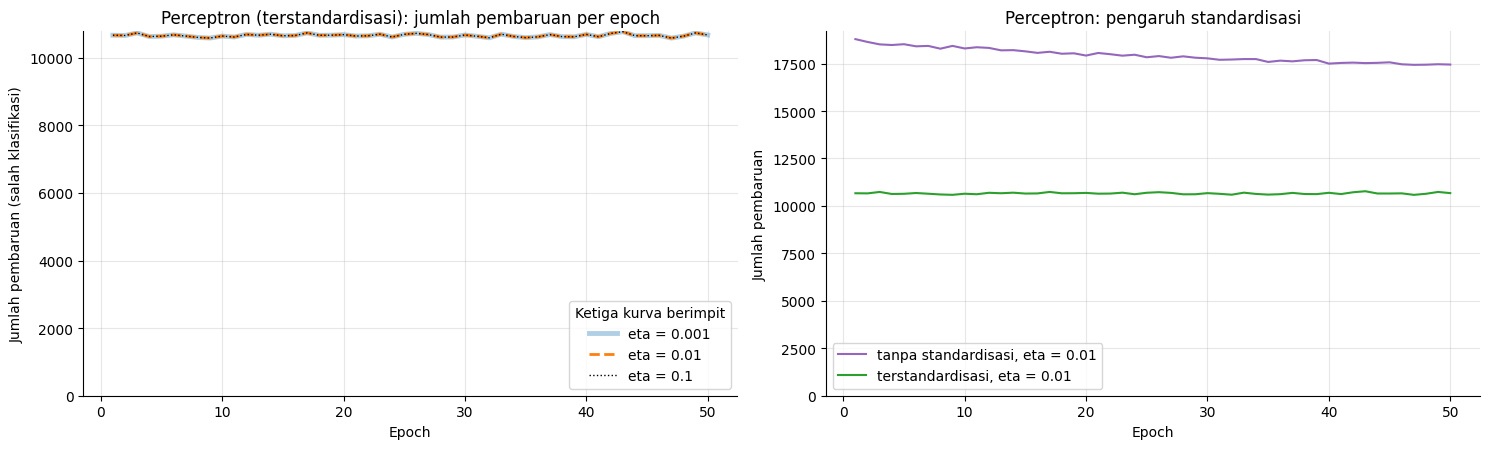

In [20]:
epochs = np.arange(1, N_EPOCHS + 1)
styles = {0.001: dict(lw=3.5, ls='-', alpha=0.35), 0.01: dict(lw=2, ls='--'), 0.1: dict(lw=1, ls=':', c='k')}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for eta in ETAS:
    axes[0].plot(epochs, models[('Perceptron', eta, True)].updates_, label=f'eta = {eta:g}', **styles[eta])
axes[0].set(title='Perceptron (terstandardisasi): jumlah pembaruan per epoch',
            xlabel='Epoch', ylabel='Jumlah pembaruan (salah klasifikasi)')
axes[0].legend(title='Ketiga kurva berimpit', loc='lower right')
mp_raw = models[('Perceptron', 0.01, False)]
axes[1].plot(epochs, mp_raw.updates_, c='tab:purple', label='tanpa standardisasi, eta = 0.01')
axes[1].plot(epochs, models[('Perceptron', 0.01, True)].updates_, c='tab:green', label='terstandardisasi, eta = 0.01')
axes[1].set(title='Perceptron: pengaruh standardisasi', xlabel='Epoch', ylabel='Jumlah pembaruan')
axes[1].legend()
for ax in axes: ax.set_ylim(bottom=0)
fig.tight_layout(); savefig(fig, '04_kurva_perceptron.png'); plt.show()

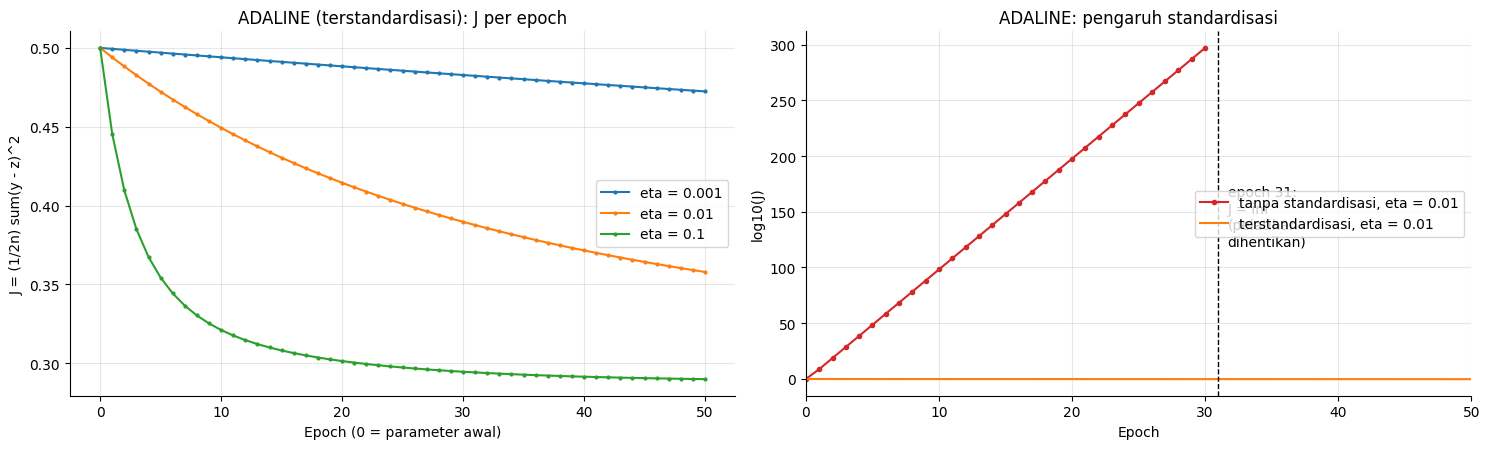

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for eta, c in zip(ETAS, ['tab:blue', 'tab:orange', 'tab:green']):
    m = models[('ADALINE', eta, True)]
    axes[0].plot(np.arange(0, m.epochs_completed_ + 1), m.cost_, c=c, marker='.', ms=4, label=f'eta = {eta:g}')
axes[0].set(title='ADALINE (terstandardisasi): J per epoch', xlabel='Epoch (0 = parameter awal)',
            ylabel='J = (1/2n) sum(y - z)^2')
axes[0].legend()
ma_raw = models[('ADALINE', 0.01, False)]
# J tanpa standardisasi mencapai ~1e297 sehingga sumbu log matplotlib meluap;
# karena itu yang diplot adalah log10(J) pada sumbu linear (informasi identik).
axes[1].plot(np.arange(0, ma_raw.epochs_completed_ + 1), np.log10(ma_raw.cost_), c='tab:red', marker='.', label='tanpa standardisasi, eta = 0.01')
axes[1].plot(np.arange(0, N_EPOCHS + 1), np.log10(models[('ADALINE', 0.01, True)].cost_), c='tab:orange', label='terstandardisasi, eta = 0.01')
if ma_raw.diverged_epoch_:
    axes[1].axvline(ma_raw.diverged_epoch_, c='k', ls='--', lw=1)
    axes[1].text(ma_raw.diverged_epoch_ + 0.7, 120, f'epoch {ma_raw.diverged_epoch_}:\nJ = inf\n(pelatihan\ndihentikan)')
axes[1].set(title='ADALINE: pengaruh standardisasi', xlabel='Epoch', ylabel='log10(J)', xlim=(0, N_EPOCHS))
axes[1].legend(loc='center right')
fig.tight_layout(); savefig(fig, '05_kurva_adaline.png'); plt.show()

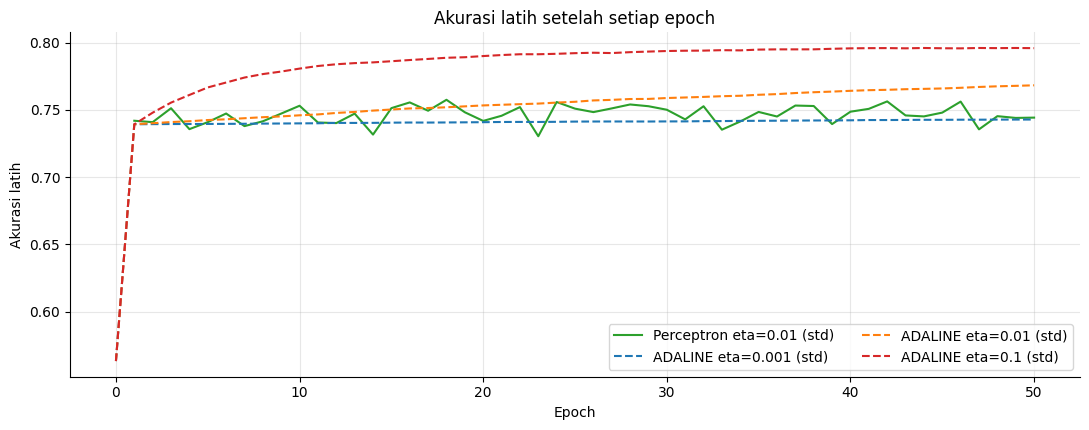

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(epochs, models[('Perceptron', 0.01, True)].train_acc_, c='tab:green', label='Perceptron eta=0.01 (std)')
for eta, c in zip(ETAS, ['tab:blue', 'tab:orange', 'tab:red']):
    ax.plot(np.arange(0, N_EPOCHS + 1), models[('ADALINE', eta, True)].train_acc_, c=c, ls='--', label=f'ADALINE eta={eta:g} (std)')
ax.set(title='Akurasi latih setelah setiap epoch', xlabel='Epoch', ylabel='Akurasi latih')
ax.legend(ncol=2); fig.tight_layout(); savefig(fig, '06_akurasi_latih_per_epoch.png'); plt.show()

### 6.4 Confusion matrix pada data uji

Urutan label: baris = label sebenarnya, kolom = prediksi, dengan urutan **[−1 (Tepat waktu), +1 (Terlambat)]**. Sel kanan-bawah = *true positive* (keterlambatan yang terdeteksi).

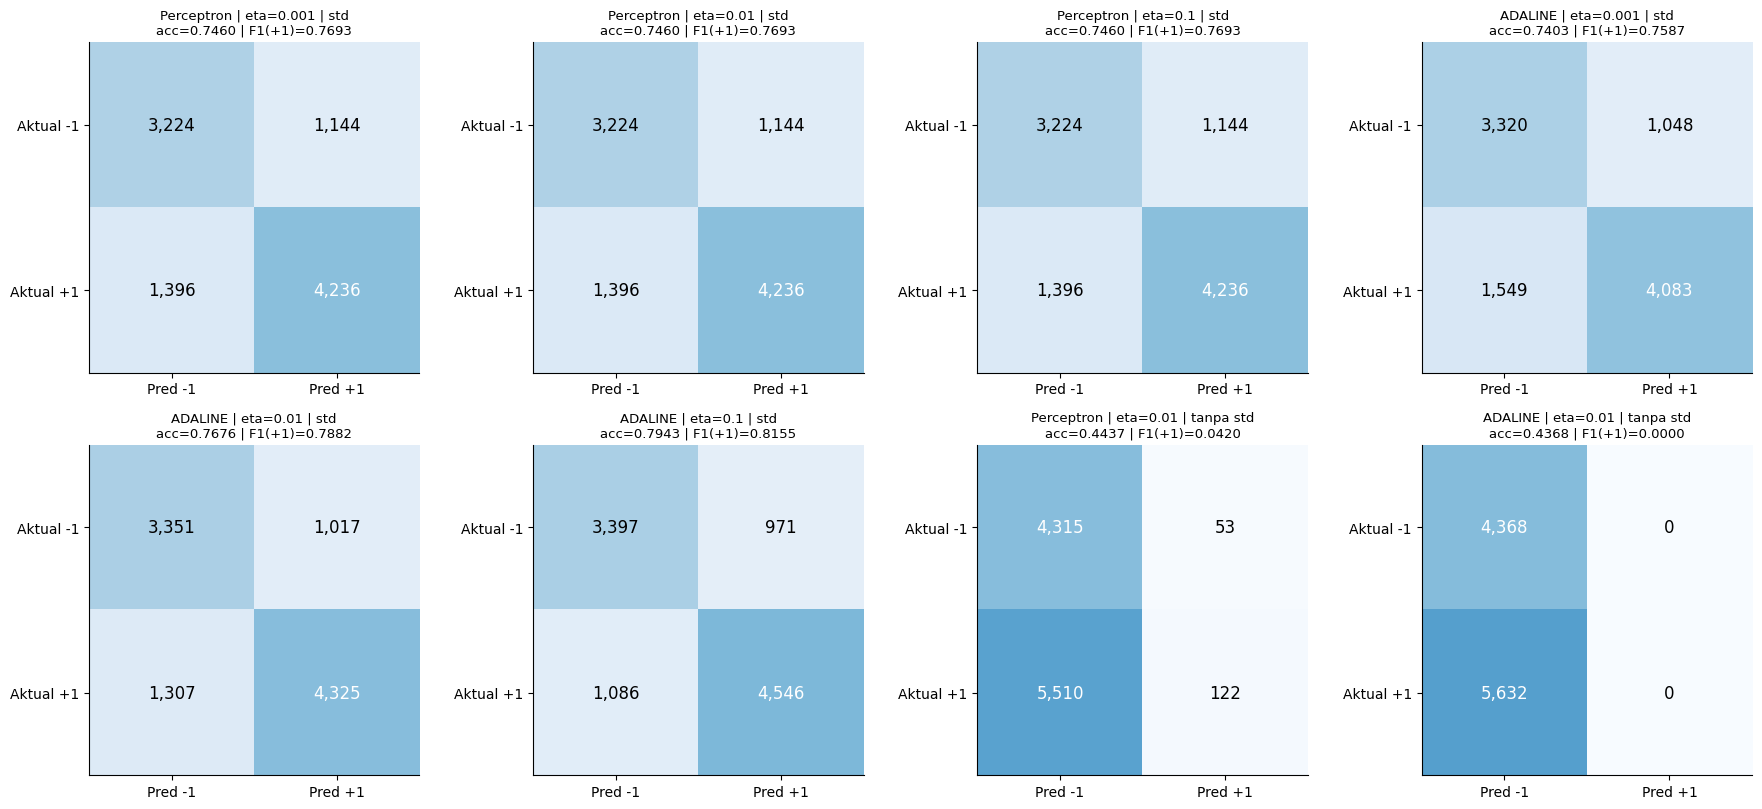

,Konfigurasi,TN,FP,FN,TP
0,Perceptron | eta=0.001 | std,3224,1144,1396,4236
1,Perceptron | eta=0.01 | std,3224,1144,1396,4236
2,Perceptron | eta=0.1 | std,3224,1144,1396,4236
3,ADALINE | eta=0.001 | std,3320,1048,1549,4083
4,ADALINE | eta=0.01 | std,3351,1017,1307,4325
5,ADALINE | eta=0.1 | std,3397,971,1086,4546
6,Perceptron | eta=0.01 | tanpa std,4315,53,5510,122
7,ADALINE | eta=0.01 | tanpa std,4368,0,5632,0


In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.2))
for ax, (key, te) in zip(axes.ravel(), test_eval.items()):
    cm = te['cm']
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=len(y_test))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=12,
                    color='white' if cm[i, j] > len(y_test) / 2.5 else 'black')
    ax.set_xticks([0, 1], ['Pred -1', 'Pred +1']); ax.set_yticks([0, 1], ['Aktual -1', 'Aktual +1'])
    ax.grid(False)
    ax.set_title(f"{cfg_label(*key)}\nacc={te['acc']:.4f} | F1(+1)={te['f1']:.4f}", fontsize=9.5)
fig.tight_layout(); savefig(fig, '07_confusion_matrix.png'); plt.show()

cm_table = pd.DataFrame([{'Konfigurasi': cfg_label(*k), 'TN': te['cm'][0, 0], 'FP': te['cm'][0, 1],
                          'FN': te['cm'][1, 0], 'TP': te['cm'][1, 1]} for k, te in test_eval.items()])
cm_table.to_csv(os.path.join(RES_DIR, 'confusion_matrix_uji.csv'), index=False)
cm_table

### 6.5 Bobot dan bias akhir

Tabel lengkap 43 bobot + bias untuk kedelapan konfigurasi disimpan di `results/bobot_bias_akhir.csv`. Di bawah ditampilkan dua konfigurasi yang paling banyak dibahas: Perceptron η = 0,01 dan ADALINE η = 0,1 (keduanya terstandardisasi). Karena fitur sudah distandardisasi, besar bobot dapat dibandingkan antar fitur. Bobot positif berarti mendorong prediksi ke arah *Terlambat*.

In [24]:
wb = pd.DataFrame({cfg_label(*k): np.append(m.w_, m.b_) for k, m in models.items()},
                  index=FEATURE_NAMES + ['bias (b)'])
wb.to_csv(os.path.join(RES_DIR, 'bobot_bias_akhir.csv'))

kP, kA = ('Perceptron', 0.01, True), ('ADALINE', 0.1, True)
wP, wA = models[kP].w_, models[kA].w_
cos_PA = wP @ wA / (np.linalg.norm(wP) * np.linalg.norm(wA))
disc = wb[[cfg_label(*kP), cfg_label(*kA)]].copy()
disc['|w| ADALINE'] = disc[cfg_label(*kA)].abs()
print(f'Bias akhir Perceptron eta=0.01 : {models[kP].b_:+.4f}')
print(f'Bias akhir ADALINE   eta=0.1  : {models[kA].b_:+.4f}')
print(f'Kemiripan kosinus arah bobot Perceptron vs ADALINE: {cos_PA:.4f}')
disc.sort_values('|w| ADALINE', ascending=False).drop(columns='|w| ADALINE').round(4)

Bias akhir Perceptron eta=0.01 : +0.2000
Bias akhir ADALINE   eta=0.1  : +0.1258
Kemiripan kosinus arah bobot Perceptron vs ADALINE: 0.8591


,Perceptron | eta=0.01 | std,ADALINE | eta=0.1 | std
weather_condition=Snow,0.6690,0.3179
weather_condition=Storm,0.3344,0.2990
order_priority,-0.2708,-0.2584
weather_condition=Rain,0.3202,0.2062
distance_km,0.3539,0.1860
bias (b),0.2000,0.1258
promised_delivery_days,0.0648,0.1106
weather_condition=Extreme Heat,0.0240,0.0841
shipping_method=Same Day,-0.1452,-0.0816
warehouse_processing_hours,0.0767,0.0792


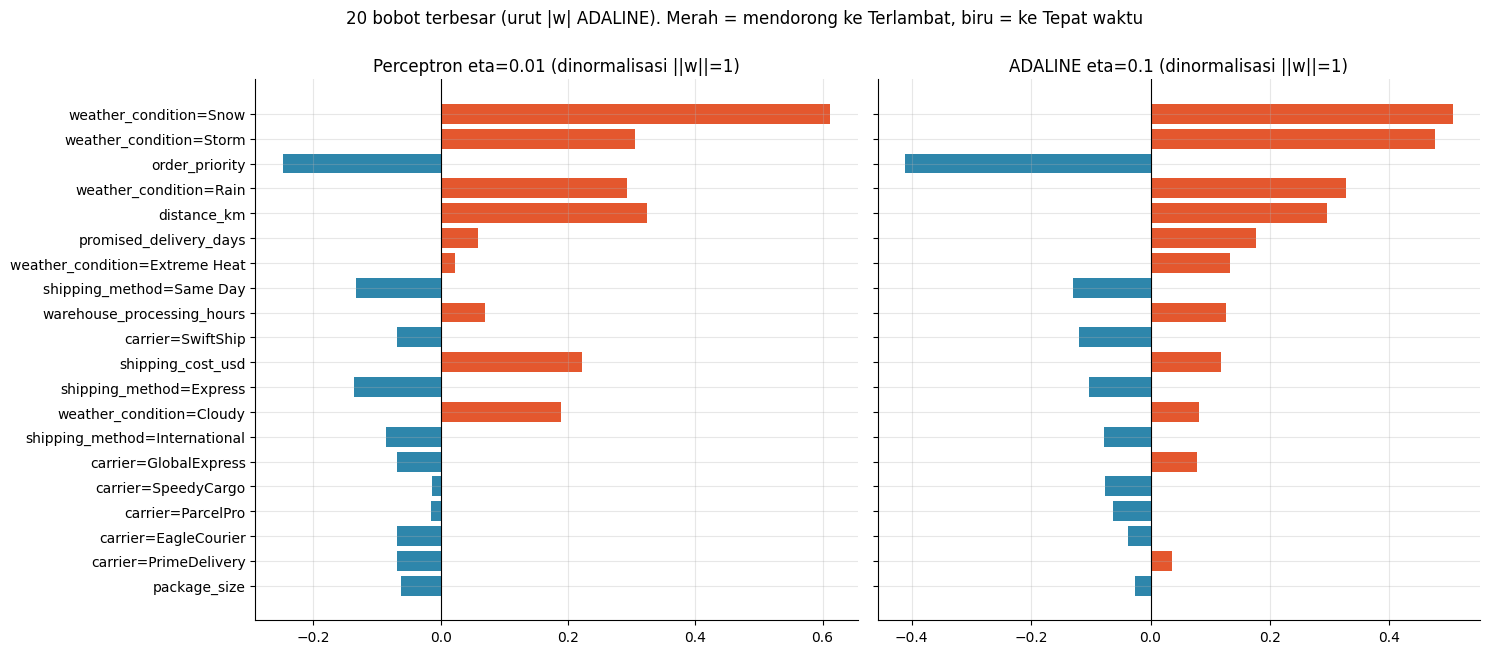

In [25]:
order = np.argsort(np.abs(wA))[::-1][:20][::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
for ax, w, t in [(axes[0], wP / np.linalg.norm(wP), 'Perceptron eta=0.01 (dinormalisasi ||w||=1)'),
                 (axes[1], wA / np.linalg.norm(wA), 'ADALINE eta=0.1 (dinormalisasi ||w||=1)')]:
    ax.barh(np.array(FEATURE_NAMES)[order], w[order], color=[C_POS if v > 0 else C_NEG for v in w[order]])
    ax.axvline(0, c='k', lw=0.8); ax.set_title(t)
fig.suptitle('20 bobot terbesar (urut |w| ADALINE). Merah = mendorong ke Terlambat, biru = ke Tepat waktu', y=1.0)
fig.tight_layout(); savefig(fig, '08_bobot_akhir.png'); plt.show()

## 7. Analisis Tambahan (Bukti Pendukung Pembahasan)

### 7.1 Mengapa ketiga η Perceptron menghasilkan kurva yang sama?

Dengan inisialisasi nol, urutan sampel tetap, dan η konstan, setiap pembaruan Perceptron bernilai ±2η·x. Akibatnya bobot setelah langkah ke-t selalu berbentuk **w_t = η·v_t** dan **b_t = η·c_t**, dengan v_t dan c_t yang tidak bergantung pada η. Tanda z = η(v_tᵀx + c_t) sama dengan tanda v_tᵀx + c_t karena η > 0, sehingga urutan prediksi dan pembaruan identik untuk semua η. Kode di bawah memeriksanya secara numerik.

In [26]:
ref = models[('Perceptron', 0.01, True)]
for eta in ETAS:
    m = models[('Perceptron', eta, True)]
    same_updates = m.updates_ == ref.updates_
    scaled = np.allclose(m.w_ / eta, ref.w_ / 0.01, rtol=1e-9, atol=1e-9) and np.isclose(m.b_ / eta, ref.b_ / 0.01)
    same_pred = np.array_equal(m.predict(X_test_std), ref.predict(X_test_std))
    print(f'eta={eta:<6g} updates identik: {same_updates} | w/eta identik: {scaled} | '
          f'prediksi uji identik: {same_pred} | ||w|| = {np.linalg.norm(m.w_):.4f}')

eta=0.001  updates identik: True | w/eta identik: True | prediksi uji identik: True | ||w|| = 0.1093
eta=0.01   updates identik: True | w/eta identik: True | prediksi uji identik: True | ||w|| = 1.0926
eta=0.1    updates identik: True | w/eta identik: True | prediksi uji identik: True | ||w|| = 10.9263


Sebagai pembanding, Perceptron dilatih ulang dengan **inisialisasi acak kecil** N(0; 0,01) yang sama untuk setiap η (seed 42). Kini rasio antara besar langkah 2η dan bobot awal berbeda untuk tiap η, sehingga lintasan pelatihan tidak lagi identik.

In [27]:
rand_rows, rand_models = [], {}
for eta in ETAS:
    m = build_model('Perceptron', eta, init='random').fit(X_train_std, y_train)
    rand_models[eta] = m
    rand_rows.append({'eta': eta, 'Update epoch 1': m.updates_[0], 'Update epoch 50': m.updates_[-1],
                      'Total update': int(np.sum(m.updates_)), 'Akurasi latih': m.train_acc_[-1],
                      'Akurasi uji': accuracy_score(y_test, m.predict(X_test_std)),
                      'Langkah 2*eta / ||w0||': 2 * eta / np.linalg.norm(m.w_history_[0])})
rand_table = pd.DataFrame(rand_rows)
rand_table.to_csv(os.path.join(RES_DIR, 'perceptron_inisialisasi_acak.csv'), index=False)
rand_table.round(4)

,eta,Update epoch 1,Update epoch 50,Total update,Akurasi latih,Akurasi uji,Langkah 2*eta / ||w0||
0,0.001,10723,10692,532103,0.7474,0.7485,0.0378
1,0.010,10659,10649,532458,0.7370,0.7337,0.3783
2,0.100,10607,10548,532551,0.7477,0.7454,3.7832


### 7.2 Apakah data terpisah secara linear? Distribusi jarak bertanda ke hyperplane

Jarak bertanda d = z / ‖w‖ = (wᵀx + b)/‖w‖ dipakai agar skala Perceptron dan ADALINE dapat dibandingkan. Jika data terpisah linear, histogram kedua kelas akan berada di sisi berlawanan dari d = 0 tanpa tumpang-tindih.

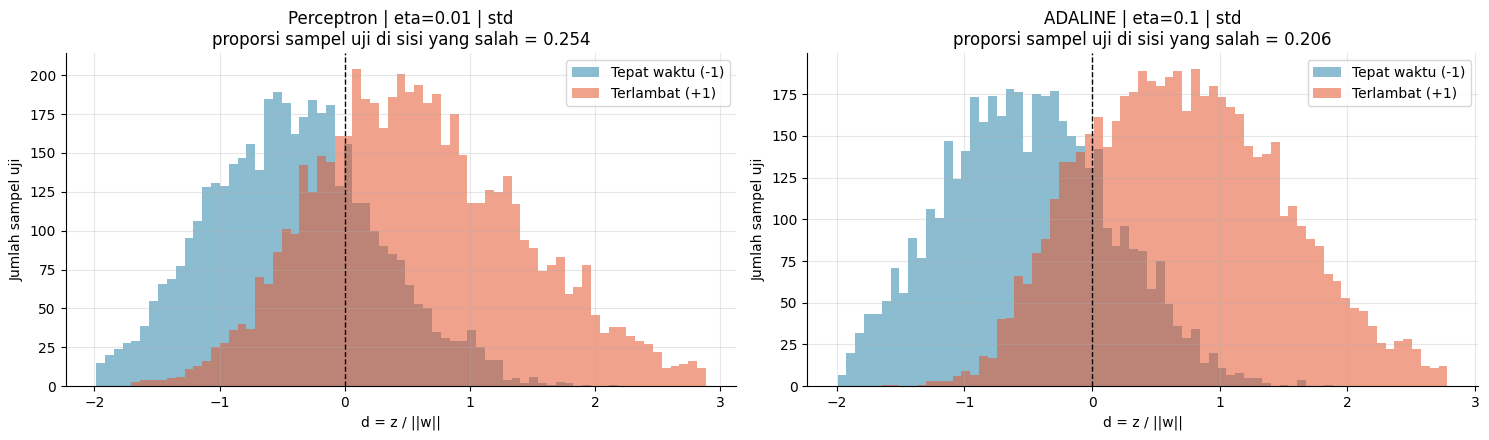

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, key in zip(axes, [kP, kA]):
    m = models[key]
    d = m.net_input(X_test_std) / np.linalg.norm(m.w_)
    bins = np.linspace(np.percentile(d, 0.5), np.percentile(d, 99.5), 70)
    ax.hist(d[y_test == -1], bins=bins, alpha=0.55, color=C_NEG, label=LABEL_NAME[-1])
    ax.hist(d[y_test == 1], bins=bins, alpha=0.55, color=C_POS, label=LABEL_NAME[1])
    ax.axvline(0, c='k', ls='--', lw=1)
    wrong = (m.predict(X_test_std) != y_test).mean()
    ax.set(title=f'{cfg_label(*key)}\nproporsi sampel uji di sisi yang salah = {wrong:.3f}',
           xlabel='d = z / ||w||', ylabel='Jumlah sampel uji')
    ax.legend()
fig.tight_layout(); savefig(fig, '09_histogram_jarak_hyperplane.png'); plt.show()

### 7.3 Visualisasi decision boundary dengan model bantu dua fitur

Model utama memakai 43 fitur sehingga batas keputusannya adalah *hyperplane* 43 dimensi yang tidak dapat digambar langsung. Untuk visualisasi, dilatih **model bantu** Perceptron (η = 0,01) dan ADALINE (η = 0,1) yang hanya memakai dua fitur numerik terstandardisasi: `distance_km` dan `warehouse_processing_hours` (dua fitur kontinu dengan korelasi terbesar terhadap label). Split, standardisasi, dan 50 epoch tetap sama. Grafik ini **bukan** model utama. Tujuannya menunjukkan bentuk batas linear dan tumpang-tindih kelas pada ruang dua dimensi.

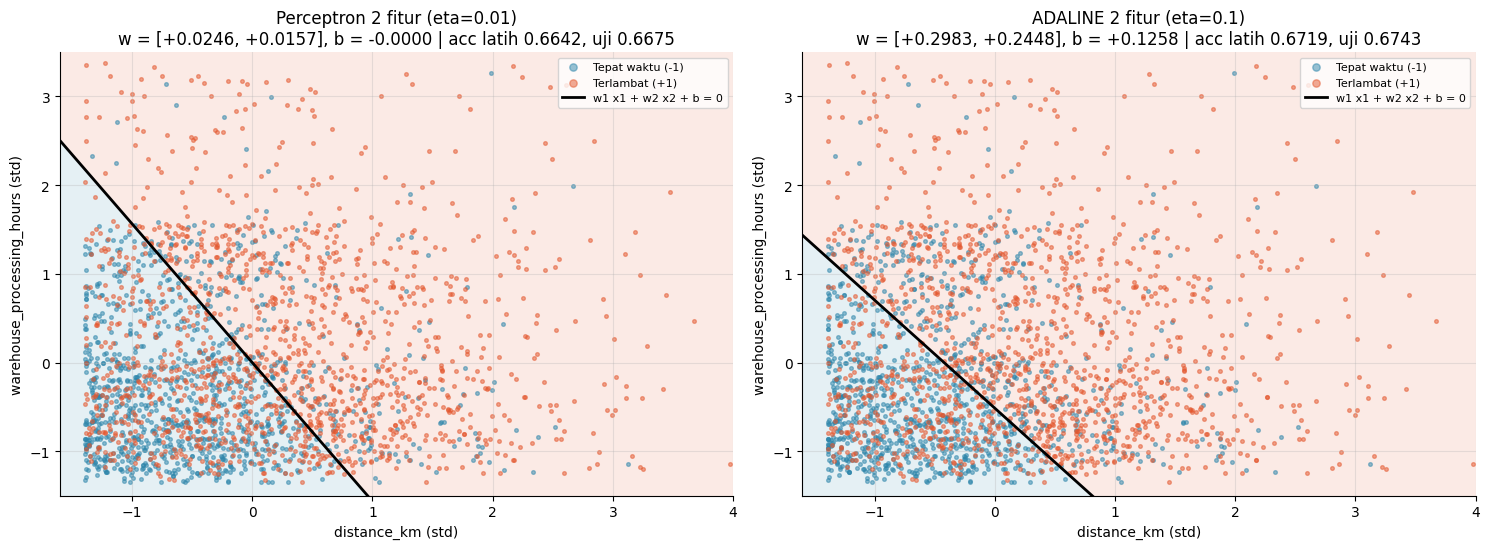

In [29]:
F2 = ['distance_km', 'warehouse_processing_hours']
c2 = [FEATURE_NAMES.index(f) for f in F2]
X2_tr, X2_te = X_train_std[:, c2], X_test_std[:, c2]
p2 = Perceptron(eta=0.01, n_epochs=N_EPOCHS).fit(X2_tr, y_train)
a2 = AdalineGD(eta=0.1, n_epochs=N_EPOCHS).fit(X2_tr, y_train)

sub2 = np.random.default_rng(SEED).choice(len(X2_te), 2500, replace=False)
xx, yy = np.meshgrid(np.linspace(-1.6, 4.0, 300), np.linspace(-1.5, 3.5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, m, t in [(axes[0], p2, 'Perceptron 2 fitur (eta=0.01)'), (axes[1], a2, 'ADALINE 2 fitur (eta=0.1)')]:
    ax.contourf(xx, yy, m.predict(grid).reshape(xx.shape), levels=[-2, 0, 2], colors=[C_NEG, C_POS], alpha=0.12)
    for lab, c in [(-1, C_NEG), (1, C_POS)]:
        s = sub2[y_test[sub2] == lab]
        ax.scatter(X2_te[s, 0], X2_te[s, 1], s=7, c=c, alpha=0.5, label=LABEL_NAME[lab])
    w1, w2_ = m.w_
    xs = np.linspace(-1.6, 4.0, 2)
    ax.plot(xs, -(w1 * xs + m.b_) / w2_, 'k-', lw=2, label='w1 x1 + w2 x2 + b = 0')
    acc_tr, acc_te = (m.predict(X2_tr) == y_train).mean(), (m.predict(X2_te) == y_test).mean()
    ax.set(xlim=(-1.6, 4.0), ylim=(-1.5, 3.5), xlabel=f'{F2[0]} (std)', ylabel=f'{F2[1]} (std)',
           title=f'{t}\nw = [{w1:+.4f}, {w2_:+.4f}], b = {m.b_:+.4f} | acc latih {acc_tr:.4f}, uji {acc_te:.4f}')
    ax.legend(loc='upper right', markerscale=2, fontsize=8)
fig.tight_layout(); savefig(fig, '10_decision_boundary_2fitur.png'); plt.show()

### 7.4 Acuan analitis ADALINE: solusi least squares dan syarat stabilitas η

ADALINE meminimalkan J = (1/2n)‖y − Aθ‖² dengan A = [X, 1] dan θ = [w; b]. Minimum globalnya dapat dihitung langsung dengan *least squares* (`np.linalg.lstsq`), sehingga dapat dipakai sebagai acuan seberapa dekat gradient descent dengan optimum. Hessian J adalah H = AᵀA/n. Batch gradient descent stabil jika **η < 2/λ_max(H)**.

In [30]:
def design(X):
    return np.hstack([X, np.ones((X.shape[0], 1))])

A_tr = design(X_train_std)
theta_ls, *_ = np.linalg.lstsq(A_tr, y_train.astype(float), rcond=None)
J_ls = float(np.sum((y_train - A_tr @ theta_ls) ** 2) / (2 * len(y_train)))
pred_ls_tr = np.where(A_tr @ theta_ls >= 0, 1, -1)
pred_ls_te = np.where(design(X_test_std) @ theta_ls >= 0, 1, -1)

ls_rows = [{'Model': 'Least squares (optimum J, acuan)', 'J latih': J_ls,
            'Akurasi latih': (pred_ls_tr == y_train).mean(), 'Akurasi uji': (pred_ls_te == y_test).mean(),
            'cos(w, w_LS)': 1.0}]
for eta in ETAS:
    m = models[('ADALINE', eta, True)]
    ls_rows.append({'Model': f'ADALINE eta={eta:g} (epoch 50)', 'J latih': m.cost_[-1],
                    'Akurasi latih': (m.predict(X_train_std) == y_train).mean(),
                    'Akurasi uji': (m.predict(X_test_std) == y_test).mean(),
                    'cos(w, w_LS)': m.w_ @ theta_ls[:-1] / (np.linalg.norm(m.w_) * np.linalg.norm(theta_ls[:-1]))})
ls_table = pd.DataFrame(ls_rows)
display(ls_table.round(4))

stab = []
for nm, X in [('Terstandardisasi', X_train_std), ('Tanpa standardisasi', X_train_raw)]:
    A = design(X)
    ev = np.linalg.eigvalsh(A.T @ A / len(A))
    stab.append({'Data': nm, 'lambda_max(H)': ev.max(), 'lambda_min(H)': ev.min(),
                 'Batas stabil 2/lambda_max': 2 / ev.max(), 'eta=0.01 x lambda_max': 0.01 * ev.max(),
                 'eta=0.1 x lambda_max': 0.1 * ev.max()})
stab_table = pd.DataFrame(stab).set_index('Data')
LAMBDA_MAX_RAW = stab_table.loc['Tanpa standardisasi', 'lambda_max(H)']
display(stab_table.style.format('{:.4g}'))
print('Pertumbuhan J per epoch (tanpa standardisasi, eta=0.01), rasio J[k]/J[k-1] untuk 5 epoch pertama:',
      np.round(np.array(ma_raw.cost_[1:6]) / np.array(ma_raw.cost_[0:5]), 3))
print(f'Prediksi teori (1 - eta*lambda_max)^2 = {(1 - 0.01 * LAMBDA_MAX_RAW) ** 2:.4g}')

,Model,J latih,Akurasi latih,Akurasi uji,"cos(w, w_LS)"
0,"Least squares (optimum J, acuan)",0.2881,0.7970,0.7947,1.0000
1,ADALINE eta=0.001 (epoch 50),0.4724,0.7428,0.7403,0.7627
2,ADALINE eta=0.01 (epoch 50),0.3578,0.7683,0.7676,0.8374
3,ADALINE eta=0.1 (epoch 50),0.2898,0.7959,0.7943,0.9913


,lambda_max(H),lambda_min(H),Batas stabil 2/lambda_max,eta=0.01 x lambda_max,eta=0.1 x lambda_max
Data,,,,,
Terstandardisasi,3.081,0.003965,0.6491,0.03081,0.3081
Tanpa standardisasi,9.467e+06,0.0005847,2.113e-07,9.467e+04,9.467e+05


Pertumbuhan J per epoch (tanpa standardisasi, eta=0.01), rasio J[k]/J[k-1] untuk 5 epoch pertama: [6.84945448e+08 8.96193998e+09 8.96198296e+09 8.96198296e+09
 8.96198296e+09]
Prediksi teori (1 - eta*lambda_max)^2 = 8.962e+09


### 7.5 Mengapa Perceptron tanpa standardisasi gagal?

In [31]:
pred_raw = test_eval[('Perceptron', 0.01, False)]['y_pred']
z_raw = mp_raw.net_input(X_test_raw)
contrib = pd.DataFrame({'bobot w': mp_raw.w_, 'rata-rata |x| (latih)': np.abs(X_train_raw).mean(0),
                        'rata-rata |w*x|': np.abs(X_train_raw * mp_raw.w_).mean(0)}, index=FEATURE_NAMES)
print(f'Distribusi prediksi uji: +1 = {(pred_raw == 1).sum():,}, -1 = {(pred_raw == -1).sum():,}')
print(f'Bias akhir b = {mp_raw.b_:+.4f}; z uji: min {z_raw.min():,.1f}, median {np.median(z_raw):,.1f}, maks {z_raw.max():,.1f}')
print(f'Akurasi latih per epoch (min / maks / akhir): {min(mp_raw.train_acc_):.4f} / {max(mp_raw.train_acc_):.4f} / {mp_raw.train_acc_[-1]:.4f}')
contrib.sort_values('rata-rata |w*x|', ascending=False).head(6).round(3)

Distribusi prediksi uji: +1 = 175, -1 = 9,825
Bias akhir b = -2023.5800; z uji: min -303,286.3, median -39,683.0, maks 24,177.0
Akurasi latih per epoch (min / maks / akhir): 0.4351 / 0.6440 / 0.4430


,bobot w,rata-rata |x| (latih),rata-rata |w*x|
distance_km,-15.600,2505.559,39086.722
shipping_cost_usd,200.788,120.960,24287.250
order_value_usd,-82.861,176.643,14636.829
order_priority,-6719.880,1.352,9087.630
warehouse_processing_hours,612.392,14.400,8818.422
promised_delivery_days,-946.800,7.207,6823.588


### 7.6 Seleksi konfigurasi dengan data validasi (data uji tidak dipakai)

Untuk menentukan konfigurasi yang direkomendasikan, data latih dibagi lagi menjadi *fit* (80%) dan *validasi* (20%), stratified dengan seed 42. Preprocessor dipelajari ulang hanya dari bagian *fit*. Kriteria utama adalah akurasi validasi, dengan F1(+1) validasi sebagai pembanding. Hasil uji konfigurasi terpilih diambil dari tabel 6.1, yang sudah ditetapkan sebelumnya.

In [32]:
i_fit, i_val = train_test_split(np.arange(len(df_train)), test_size=VAL_SIZE,
                                stratify=y_train, random_state=SEED)
prep_val = Preprocessor(NUM_FEATURES, ORD_FEATURES, NOM_FEATURES, standardize=True).fit(df_train.iloc[i_fit])
X_fit, X_val = prep_val.transform(df_train.iloc[i_fit]), prep_val.transform(df_train.iloc[i_val])
y_fit, y_val = y_train[i_fit], y_train[i_val]

val_rows = []
for name in ['Perceptron', 'ADALINE']:
    for eta in ETAS:
        m = build_model(name, eta).fit(X_fit, y_fit)
        yv = m.predict(X_val)
        val_rows.append({'Model': name, 'eta': eta, 'Akurasi fit': (m.predict(X_fit) == y_fit).mean(),
                         'Akurasi validasi': accuracy_score(y_val, yv),
                         'F1(+1) validasi': f1_score(y_val, yv, pos_label=POS_LABEL)})
val_table = pd.DataFrame(val_rows)
val_table.to_csv(os.path.join(RES_DIR, 'seleksi_validasi.csv'), index=False)
display(val_table.round(4))

best = val_table.loc[val_table['Akurasi validasi'].idxmax()]
bk = (best['Model'], best['eta'], True)
print(f"Konfigurasi terpilih (validasi): {best['Model']} eta={best['eta']:g} -> akurasi validasi {best['Akurasi validasi']:.4f}")
print(f"Kinerja uji konfigurasi tsb (tabel 6.1): akurasi {test_eval[bk]['acc']:.4f}, "
      f"precision(+1) {test_eval[bk]['prec']:.4f}, recall(+1) {test_eval[bk]['rec']:.4f}, F1(+1) {test_eval[bk]['f1']:.4f}")

,Model,eta,Akurasi fit,Akurasi validasi,F1(+1) validasi
0,Perceptron,0.001,0.6822,0.6759,0.6916
1,Perceptron,0.010,0.6822,0.6759,0.6916
2,Perceptron,0.100,0.6822,0.6759,0.6916
3,ADALINE,0.001,0.7409,0.7531,0.7714
4,ADALINE,0.010,0.7667,0.7765,0.7967
5,ADALINE,0.100,0.7955,0.7996,0.8204


Konfigurasi terpilih (validasi): ADALINE eta=0.1 -> akurasi validasi 0.7996
Kinerja uji konfigurasi tsb (tabel 6.1): akurasi 0.7943, precision(+1) 0.8240, recall(+1) 0.8072, F1(+1) 0.8155


### 7.7 Osilasi Perceptron dan ide *pocket*

Pada data yang tidak terpisah linear, bobot Perceptron di akhir epoch 50 belum tentu yang terbaik, karena bobot terus "melompat" setiap ada sampel salah. Gagasan *pocket algorithm* (Gallant, 1990) adalah menyimpan bobot dengan kesalahan latih terkecil. Di bawah, epoch terbaik dipilih **berdasarkan akurasi latih** (bukan data uji) dari riwayat yang sudah tercatat.

In [33]:
best_ep = int(np.argmax(ref.train_acc_)) + 1          # epoch 1..50
w_pk, b_pk = ref.w_history_[best_ep], ref.b_history_[best_ep]
acc_pk = (np.where(X_test_std @ w_pk + b_pk >= 0, 1, -1) == y_test).mean()
acc_arr = np.array(ref.train_acc_)
print(f'Akurasi latih Perceptron eta=0.01 per epoch: min {acc_arr.min():.4f}, maks {acc_arr.max():.4f}, '
      f'rata-rata {acc_arr.mean():.4f}, simpangan baku {acc_arr.std():.4f}')
print(f'Epoch dengan akurasi latih terbaik = {best_ep} ({acc_arr[best_ep - 1]:.4f}) -> akurasi uji bobot tsb = {acc_pk:.4f}')
print(f"Bobot epoch 50 (dipakai di tabel utama)        -> akurasi uji = {test_eval[kP]['acc']:.4f}")

Akurasi latih Perceptron eta=0.01 per epoch: min 0.7304, maks 0.7575, rata-rata 0.7465, simpangan baku 0.0066
Epoch dengan akurasi latih terbaik = 18 (0.7575) -> akurasi uji bobot tsb = 0.7600
Bobot epoch 50 (dipakai di tabel utama)        -> akurasi uji = 0.7460


### 7.8 Pembanding tambahan: `sklearn.linear_model.Perceptron`

Hanya dipakai sebagai pemeriksaan silang, bukan model utama. Konfigurasinya disamakan: η = 0,01, 50 epoch, tanpa pengacakan, `tol=None`. Perbedaan yang diharapkan: scikit-learn memperbarui bobot ketika y·z ≤ 0 dengan langkah η·y (bukan 2η), dan memprediksi +1 hanya jika z > 0.

In [34]:
from sklearn.linear_model import Perceptron as SkPerceptron
sk = SkPerceptron(eta0=0.01, max_iter=N_EPOCHS, tol=None, shuffle=False,
                  fit_intercept=True, random_state=SEED)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sk.fit(X_train_std, y_train)
cos_sk = (sk.coef_.ravel() @ wP) / (np.linalg.norm(sk.coef_) * np.linalg.norm(wP))
print(f'sklearn Perceptron : akurasi latih {sk.score(X_train_std, y_train):.4f}, uji {sk.score(X_test_std, y_test):.4f}')
print(f'Perceptron mandiri : akurasi latih {(ref.predict(X_train_std) == y_train).mean():.4f}, uji {test_eval[kP]["acc"]:.4f}')
print(f'Kemiripan kosinus arah bobot: {cos_sk:.4f}')

sklearn Perceptron : akurasi latih 0.7576, uji 0.7569
Perceptron mandiri : akurasi latih 0.7443, uji 0.7460
Kemiripan kosinus arah bobot: 0.9423


## 8. Pembahasan

### 8.1 Apakah data menunjukkan indikasi dapat dipisahkan secara linear?

**Tidak.** Kesimpulan ini didasarkan pada perilaku pelatihan dan pola data, bukan hanya pada akurasi uji:

1. **Perceptron tidak pernah konvergen.** Pada data terstandardisasi, jumlah pembaruan per epoch tetap sekitar 10.600–10.700 dari 40.000 sampel (10.642 di epoch 10; 10.673 di epoch 30; 10.674 di epoch 50) dan tidak menurun (Gambar `04`). Teorema konvergensi Perceptron menjamin pembaruan berhenti setelah jumlah langkah terhingga **jika** data terpisah linear. Dalam 50 epoch, sekitar 26,7% sampel masih memicu pembaruan di setiap epoch. Ini indikasi kuat bahwa hyperplane pemisah sempurna tidak ada.
2. **Akurasi latih Perceptron berosilasi** antara 0,7304 dan 0,7575 (simpangan baku 0,0066), tanpa tren naik (Gambar `06`, Bagian 7.7). Bobot terus "ditarik" bolak-balik oleh sampel yang tidak mungkin benar semuanya.
3. **Optimum least squares pun tidak mendekati nol.** Minimum global J untuk model linear adalah J_LS = 0,2881 (Bagian 7.4). Jika data terpisah linear dengan margin, J dapat jauh lebih kecil. Dengan J_LS ≈ 0,29, residual rata-ratanya besar.
4. **Distribusi jarak bertanda d = z/‖w‖ tumpang-tindih** di sekitar d = 0 untuk kedua model (Bagian 7.2). Pada model linear terbaik (ADALINE η = 0,1), 20,6% sampel uji tetap berada di sisi hyperplane yang salah.
5. **Pola data mendukung hal yang sama.** PCA 2D (Gambar `03`) dan model bantu dua fitur (Bagian 7.3, akurasi uji ≈ 0,67) memperlihatkan kedua kelas bercampur. EDA juga menunjukkan bahwa cuaca bersalju/badai meningkatkan peluang terlambat, tetapi di setiap kategori tetap ada kedua kelas.

Artinya, kedua model hanya dapat menemukan **hyperplane kompromi**. Batas atas akurasi model linear pada data ini sekitar 79–80%.

### 8.2 Bagaimana Perceptron dan ADALINE menggunakan error yang berbeda untuk memperbarui bobot?

| Aspek | Perceptron | ADALINE (Delta Rule) |
|---|---|---|
| Error | diskret: y − ŷ ∈ {−2, 0, +2} | kontinu: e = y − z (keluaran linear) |
| Kapan memperbarui | hanya saat salah klasifikasi | selalu, selama z ≠ y |
| Besar langkah | selalu ±2η·x, tidak bergantung jarak ke batas | sebanding dengan besar error setiap sampel |
| Cakupan per langkah | satu sampel (online) | seluruh batch (rata-rata gradient) |
| Tujuan implisit | mengurangi jumlah salah klasifikasi | meminimalkan J = (1/2n)Σe² |

Konsekuensinya terlihat pada hasil:

- **ADALINE η = 0,1** mencapai J = 0,2898, hanya 0,6% di atas J_LS = 0,2881. Arah bobotnya hampir sama dengan solusi least squares (kosinus 0,9913), dan akurasi ujinya 0,7943 (least squares: 0,7947). Gradient descent benar-benar menuju optimum fungsi objektifnya.
- **Perceptron** berakhir pada bobot yang ditentukan oleh beberapa ratus sampel salah terakhir. Kosinus arah bobotnya dengan ADALINE hanya 0,8591. Fitur yang praktis tidak berguna menurut ADALINE (mis. `product_category=Home & Kitchen`: ADALINE +0,0005, Perceptron −0,1352; `customer_segment=Premium`: +0,0008 vs −0,1328) mendapat bobot cukup besar pada Perceptron. Ini "noise" dari pembaruan diskret, bukan pola data.
- Kedua model **sepakat pada fitur dominan**: `weather_condition=Snow`, `=Storm`, `=Rain` dan `distance_km` mendorong ke *Terlambat*. `order_priority` yang lebih tinggi serta `shipping_method=Same Day`/`Express` mendorong ke *Tepat waktu*. Pola ini konsisten dengan EDA.

### 8.3 Bagaimana η, jumlah epoch, dan standardisasi memengaruhi pelatihan?

**Learning rate pada Perceptron: hasil tidak berubah, dan ini sah.** Ketiga η menghasilkan jumlah pembaruan, akurasi, confusion matrix, dan prediksi yang **identik**. Hanya norma bobotnya yang berskala (‖w‖ = 0,1093; 1,0926; 10,9263, tepat 10× setiap kenaikan η). Penyebabnya: dengan w₀ = 0, b₀ = 0, urutan sampel tetap, dan η konstan, setiap pembaruan bernilai ±2η·x sehingga w_t = η·v_t. Karena η > 0, tanda z tidak bergantung pada η. Bagian 7.1 memverifikasinya secara numerik (`w/η` identik). Sebagai kontrol, dengan **inisialisasi acak kecil** ketiga η menghasilkan akurasi uji yang berbeda (0,7485; 0,7337; 0,7454), karena rasio langkah 2η terhadap ‖w₀‖ kini berbeda (0,04; 0,38; 3,78).

**Learning rate pada ADALINE: sangat berpengaruh.** Setelah 50 epoch, J = 0,4724 (η = 0,001), 0,3578 (η = 0,01), dan 0,2898 (η = 0,1), dengan akurasi uji 0,7403; 0,7676; 0,7943. Dengan η kecil, langkah gradient terlalu pendek sehingga model belum mencapai optimum dalam 50 epoch. Laju penurunan J diatur oleh η·λ (λ = nilai eigen Hessian H = AᵀA/n). Pada data terstandardisasi λ_max = 3,081, sehingga batas stabil η < 2/λ_max = 0,649. Ketiga η berada di bawah batas ini dan tidak perlu disesuaikan.

**Jumlah epoch.** Pada Perceptron, kondisi epoch 10, 30, dan 50 praktis sama (pembaruan ≈ 10.650; akurasi latih 0,7531 → 0,7501 → 0,7443). Menambah epoch tidak membantu karena data tidak terpisah linear, dan bobot epoch terakhir belum tentu yang terbaik. Bobot epoch 18 memiliki akurasi latih tertinggi (0,7575) dan akurasi uji 0,7600, lebih baik daripada bobot epoch 50 (0,7460). Inilah motivasi *pocket algorithm*. Pada ADALINE, J terus turun secara monoton. Untuk η = 0,1, J@10 = 0,3210, J@30 = 0,2945, dan J@50 = 0,2898 (hampir jenuh). Untuk η = 0,001, J@50 = 0,4724 masih jauh dari optimum sehingga epoch tambahan masih akan bermanfaat.

**Standardisasi: penentu stabilitas.**

- **ADALINE tanpa standardisasi (η = 0,01) divergen.** J naik sekitar 9×10⁹ kali per epoch, mencapai 1,4×10²⁹⁷ pada epoch 30, lalu menjadi tak hingga pada **epoch 31**. Pelatihan dihentikan dan parameter epoch 30 dipakai. Penyebabnya terukur: tanpa standardisasi λ_max(H) = 9,467×10⁶ (didominasi `distance_km` yang bernilai ribuan), sehingga batas stabil η < 2,1×10⁻⁷. η = 0,01 berarti η·λ_max ≈ 9,5×10⁴ ≫ 2. Rasio pertumbuhan teoretis (1 − ηλ_max)² = 8,96×10⁹ sama persis dengan rasio yang teramati. Parameter yang meledak membuat semua prediksi uji bernilai −1 (akurasi 0,4368 = proporsi kelas −1; recall(+1) = 0).
- **Perceptron tanpa standardisasi tidak meledak, tetapi gagal belajar.** Perceptron tidak meminimalkan fungsi kuadrat sehingga tidak ada divergensi numerik. Namun z didominasi fitur berskala besar (rata-rata |w·x| `distance_km` ≈ 39.087, sedangkan fitur one-hot hanya 0/1). Jumlah pembaruan tetap 17.400–18.300 per epoch, akurasi latih melompat antara 0,4351 dan 0,6440, dan model akhir hanya memprediksi +1 pada 175 dari 10.000 sampel uji. Akurasi uji 0,4437 dan recall(+1) 0,0217, lebih buruk daripada baseline selalu menebak mayoritas (0,5632).

### 8.4 Apakah akurasi yang sama menunjukkan proses pembelajaran yang sama?

**Tidak.** Dua contoh dari eksperimen ini:

1. **Tiga Perceptron terstandardisasi** memiliki akurasi identik (0,7460) dan lintasan pembelajaran yang juga identik. Yang berbeda hanya skala bobotnya. Di sini akurasi sama memang berasal dari proses yang sama (setara secara matematis).
2. **Perceptron η = 0,01 (uji 0,7460) vs ADALINE η = 0,001 (uji 0,7403)** memiliki akurasi hampir sama, tetapi prosesnya sangat berbeda. Perceptron mencapai akurasinya lewat lebih dari 530.000 pembaruan diskret yang berosilasi, sedangkan ADALINE η = 0,001 baru menempuh 50 langkah gradient yang mulus dan belum konvergen (J = 0,4724 vs optimum 0,2881). ADALINE η = 0,001 memiliki precision lebih tinggi (0,7958 vs 0,7874) tetapi recall lebih rendah (0,7250 vs 0,7521). Dengan akurasi mirip, kedua model melakukan **jenis kesalahan yang berbeda**.

Bukti lain: pada seleksi validasi (Bagian 7.6), Perceptron yang dilatih pada subset 80% data latih hanya mencapai akurasi validasi 0,6759, jauh di bawah 0,7460 pada eksperimen utama. ADALINE stabil (0,7996 vs 0,7943). Ini menunjukkan bobot akhir Perceptron sangat sensitif terhadap urutan/subset data, sedangkan ADALINE tidak.

### 8.5 Keterbatasan dan langkah pengembangan

**Keterbatasan**

1. **Batas model linear.** Perceptron dan ADALINE hanya membentuk satu hyperplane. Model linear optimum pun (least squares) berhenti di akurasi uji 0,7947. Interaksi antar fitur (mis. cuaca buruk × jarak jauh × metode pengiriman) tidak dapat direpresentasikan.
2. **Bobot akhir Perceptron tidak stabil.** Bobot bergantung pada sampel salah terakhir. Akurasi akhirnya bergantung pada kapan pelatihan dihentikan (0,7460 di epoch 50 vs 0,7600 di epoch 18).
3. **Dataset.** Data berasal dari Kaggle dan menyerupai data sintetis (tidak ada missing value maupun duplikat), sehingga generalisasi ke data operasional nyata belum teruji. Kelas sedikit tidak seimbang (56,3% terlambat). Karena itu precision/recall/F1 kelas positif dilaporkan bersama baseline mayoritas 0,5632.
4. **Evaluasi satu split.** Hasil berasal dari satu pembagian 80:20 dengan seed 42. Variasi antar split belum diukur (misalnya dengan k-fold cross-validation).
5. **Encoding.** Ordinal untuk `package_size`/`order_priority` mengasumsikan jarak antar level sama. One-hot menambah fitur menjadi 43, dan beberapa di antaranya hampir tidak berkontribusi.

**Langkah pengembangan**

1. **Pocket / averaged perceptron** (Gallant, 1990) untuk menstabilkan bobot Perceptron pada data tak terpisah linear. Bagian 7.7 sudah menunjukkan potensinya (+1,4 poin akurasi).
2. **Mini-batch / stochastic ADALINE dan pengaturan η adaptif** agar η kecil tetap konvergen dalam waktu wajar.
3. **Regresi logistik** (aktivasi sigmoid + cross-entropy) agar keluaran dapat dibaca sebagai probabilitas keterlambatan.
4. **Multi-Layer Perceptron** dengan lapisan tersembunyi untuk menangkap batas keputusan non-linear, sesuai materi pertemuan berikutnya.
5. **Rekayasa fitur dan validasi silang**: fitur interaksi (mis. `distance_km × weather`), seleksi fitur, serta k-fold cross-validation untuk mengukur kestabilan hasil.

## 9. Kesimpulan

Tujuan tugas ini adalah memprediksi keterlambatan pengiriman (+1 = Terlambat) dari 14 atribut pesanan (43 fitur setelah encoding) dengan Perceptron dan ADALINE yang diimplementasikan mandiri. Berdasarkan delapan pelatihan utama dan analisis pendukung:

1. **Kedua model berhasil mempelajari pola yang bermakna** dan melampaui baseline mayoritas (0,5632). Konfigurasi terbaik, **ADALINE η = 0,1 terstandardisasi**, dipilih melalui data validasi (akurasi validasi 0,7996). Kinerjanya pada data uji: akurasi **0,7943**, precision(+1) 0,8240, recall(+1) 0,8072, F1(+1) 0,8155. Perceptron terstandardisasi mencapai akurasi uji 0,7460 (F1(+1) 0,7693).
2. **Data tidak terpisah linear.** Perceptron tetap melakukan sekitar 10.670 pembaruan per epoch hingga epoch 50, akurasi latihnya berosilasi, distribusi z kedua kelas tumpang-tindih, dan optimum least squares hanya mencapai J = 0,2881 dengan akurasi uji 0,7947. ADALINE η = 0,1 sudah berada di titik optimum model linear tersebut. Keterbatasan yang tersisa adalah keterbatasan **kelas model**, bukan kegagalan optimisasi.
3. **Perbedaan error menentukan perilaku belajar.** Error kontinu ADALINE menghasilkan penurunan J yang mulus dan bobot yang dekat dengan solusi optimum. Error diskret Perceptron menghasilkan bobot yang berosilasi dan sensitif terhadap urutan data.
4. **Pengaruh η berbeda pada kedua model.** Pada Perceptron berinisialisasi nol, η hanya menskalakan bobot sehingga ketiga konfigurasi identik (terbukti analitis dan numerik). Pada ADALINE, η menentukan kecepatan konvergensi dalam 50 epoch.
5. **Standardisasi wajib.** Tanpa standardisasi, ADALINE divergen pada epoch 31 karena η·λ_max ≫ 2, dan Perceptron jatuh ke akurasi 0,4437, di bawah baseline.

Akurasi sekitar 79% sudah merupakan batas yang wajar untuk model neuron tunggal pada kasus ini. Peningkatan berikutnya memerlukan model non-linear (MLP) atau rekayasa fitur, bukan sekadar menambah epoch atau mengganti η.

## 10. Daftar Pustaka

1. Rosenblatt, F. (1958). The perceptron: A probabilistic model for information storage and organization in the brain. *Psychological Review*, 65(6), 386–408. https://doi.org/10.1037/h0042519
2. Widrow, B., & Hoff, M. E. (1960). Adaptive switching circuits. *IRE WESCON Convention Record*, Part 4, 96–104. https://isl.stanford.edu/~widrow/papers/c1960adaptiveswitching.pdf
3. Pratama, N., Anrahvi, R., Tambal, A., & Singh, A. (2025). Classification of E-Commerce Shipping Timeliness Using Supervised Learning Algorithm. *Public Research Journal of Engineering, Data Technology and Computer Science (PREDATECS)*, 3(1). https://doi.org/10.57152/predatecs.v3i1.1855
4. LeCun, Y., Bottou, L., Orr, G. B., & Müller, K.-R. (1998). Efficient BackProp. Dalam *Neural Networks: Tricks of the Trade* (LNCS 1524), 9–50. Springer. https://doi.org/10.1007/3-540-49430-8_2
5. Gallant, S. I. (1990). Perceptron-based learning algorithms. *IEEE Transactions on Neural Networks*, 1(2), 179–191. https://doi.org/10.1109/72.80230
6. Raschka, S., & Mirjalili, V. (2019). *Python Machine Learning* (3rd ed.). Packt Publishing. Kode bab 2: https://github.com/rasbt/python-machine-learning-book-3rd-edition/tree/master/ch02
7. Raschka, S. (tanpa tahun). Adaline: Adaptive Linear Neuron Classifier. Dokumentasi mlxtend. https://rasbt.github.io/mlxtend/user_guide/classifier/Adaline/ (diakses 6 Oktober 2026).
8. Pedregosa, F., *et al.* (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. https://scikit-learn.org/stable/
9. E-commerce Delivery and Shipping Data 2026 (2026). Kaggle, lisensi CC0 1.0. https://www.kaggle.com/datasets/datascikhan/e-commerce-delivery-and-shipping-data-2026

---
**Pernyataan bantuan AI.** Asisten AI generatif dipakai untuk membantu menyusun kerangka kode, visualisasi, dan draf narasi. Cara verifikasi hasil: (1) perhitungan manual dicek dengan `assert` terhadap kelas `Perceptron`/`AdalineGD`; (2) standardisasi buatan sendiri dicek identik dengan `StandardScaler` yang di-*fit* pada data latih; (3) tidak ada irisan indeks latih/uji (`assert`); (4) invariansi η Perceptron diverifikasi numerik; (5) ADALINE dicek silang dengan solusi least squares tertutup dan Perceptron dengan `sklearn.linear_model.Perceptron`; (6) notebook dijalankan ulang dari awal (Python 3.13.7, `SEED = 42`, dependensi di `requirements.txt`) dengan hasil yang sama. Setiap anggota kelompok bertanggung jawab memahami dan dapat menjelaskan seluruh isi notebook.